# NCA GEDI waveforms at field vegetation-state sample locations

This notebook links the existing **K5 m=1.33 vegetation clustering products** to the retained NCA GEDI shots and builds representative waveform panels for each diagnostic vegetation state.

Inputs already produced by the project:

- K5 parent assignments: `C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived\NCA_FCM_K5_m1p33_parent_assignments.csv`
- K5 diagnostic subclusters: `C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv`
- retained A1/A5 GEDI shot table and cached shot coordinates from the NCA waveform diagnostics.

The diagnostic response is `diagnostic_state_id`; parent classes are `parent_cluster_k5`.

This is a **spatial correspondence diagnostic**. Field year is preserved because a field observation and a GEDI footprint can coincide spatially without being contemporaneous.

**Correction:** this version does not require the coordinate cache to exist beforehand. If absent, retained-shot coordinates are rebuilt directly from the stored L2A subset and then cached for subsequent runs.

In [15]:
# =============================================================================
# 0. IMPORTS, PATHS, CONTROLS
# =============================================================================
from pathlib import Path
import math, re, warnings
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pyproj import Transformer
from tqdm.auto import tqdm

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 240)

SUBCLUSTER_ASSIGNMENTS_PATH = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters"
    r"\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv"
)

GEDI_ROOT = Path(r"A:\NCA_DATA\GEDI\NCA_template_bbox_L1B_L2A")
SUBSET_ROOT = GEDI_ROOT / "NCA_spatial_subset_h5"
L1B_DIR = SUBSET_ROOT / "GEDI01_B"
L2A_DIR = SUBSET_ROOT/ "GEDI02_A"
A1A5_DIR = SUBSET_ROOT / "algorithm1_vs_algorithm5_vertical_v2"
CACHE_VERSION = "A1_A5_rx_nummodes_v1"
RETAINED_SHOTS_PATH = A1A5_DIR / f"NCA_A1_A5_retained_shots_{CACHE_VERSION}.pkl"
SHOT_COORD_CACHE = A1A5_DIR / "NCA_A1_A5_shot_coordinates.pkl"

FIELD_CRS = "EPSG:26911"
MATCH_RADIUS_M = 25.0
N_REPRESENTATIVES_PER_STATE = 3
MAX_STATE_WAVEFORMS = 100
HEIGHT_MIN_M = -5.0
HEIGHT_MAX_M = 20.0
FIELD_YEARS = None       # e.g. [2025, 2026]

OUT_DIR = A1A5_DIR / "field_state_waveform_diagnostic"
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPRESENTATIVE_TABLE_PATH = OUT_DIR / "NCA_field_state_GEDI_representatives.csv"

if SHOT_COORD_CACHE.exists():
    print("Coordinate cache:", SHOT_COORD_CACHE)
else:
    print(
        "Coordinate cache not found; "
        "coordinates will be reconstructed from L2A."
    )

print("State assignments:", SUBCLUSTER_ASSIGNMENTS_PATH)
print("GEDI shots:       ", RETAINED_SHOTS_PATH)
#print("GEDI coordinates: ", SHOT_COORD_CACHE)
print("Match radius:     ", MATCH_RADIUS_M, "m")

Coordinate cache not found; coordinates will be reconstructed from L2A.
State assignments: C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv
GEDI shots:        A:\NCA_DATA\GEDI\NCA_template_bbox_L1B_L2A\NCA_spatial_subset_h5\algorithm1_vs_algorithm5_vertical_v2\NCA_A1_A5_retained_shots_A1_A5_rx_nummodes_v1.pkl
Match radius:      25.0 m


In [16]:
# =============================================================================
# LOAD DIAGNOSTIC STATES + AUTHORITATIVE PLOT COORDINATES
# =============================================================================

STATE_PATH = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters"
    r"\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv"
)

COORD_PATH = Path(
    r"C:\NCA_DATA\Analysis\2016thru2026_plots_master.csv"
)


# -----------------------------------------------------------------------------
# Load state assignments
# -----------------------------------------------------------------------------

states = pd.read_csv(
    STATE_PATH,
    low_memory=False,
)

states.columns = (
    states.columns
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)


# -----------------------------------------------------------------------------
# Normalize plot identifier
# -----------------------------------------------------------------------------

if "Plot" in states.columns:

    states["Plot"] = (
        states["Plot"]
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

elif "PlotID" in states.columns:

    states["Plot"] = (
        states["PlotID"]
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

else:

    raise KeyError(
        "State table requires Plot or PlotID."
    )


states["Year"] = pd.to_numeric(
    states["Year"],
    errors="raise",
).astype(int)


# -----------------------------------------------------------------------------
# Load coordinate master
# -----------------------------------------------------------------------------

coords = pd.read_csv(
    COORD_PATH,
    low_memory=False,
)

coords.columns = (
    coords.columns
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)


if "Plot" not in coords.columns:

    if "PlotID" in coords.columns:

        coords["Plot"] = (
            coords["PlotID"]
            .astype(str)
            .str.strip()
            .str.replace(r"\.0$", "", regex=True)
        )

    else:

        raise KeyError(
            "Coordinate master requires Plot or PlotID."
        )


coords["Plot"] = (
    coords["Plot"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

coords["Year"] = pd.to_numeric(
    coords["year"],
    errors="raise",
).astype(int)


required_coord_cols = {
    "Plot",
    "Year",
    "Easting",
    "Northing",
}

missing = (
    required_coord_cols
    - set(coords.columns)
)

if missing:

    raise KeyError(
        f"Coordinate master missing: {sorted(missing)}"
    )


# -----------------------------------------------------------------------------
# Keep only spatial fields
# -----------------------------------------------------------------------------

coords = coords[
    [
        "Plot",
        "Year",
        "Easting",
        "Northing",
    ]
].copy()


coords["Easting"] = pd.to_numeric(
    coords["Easting"],
    errors="coerce",
)

coords["Northing"] = pd.to_numeric(
    coords["Northing"],
    errors="coerce",
)


# -----------------------------------------------------------------------------
# QA coordinate identity before merge
# -----------------------------------------------------------------------------

coord_dupes = coords.duplicated(
    [
        "Plot",
        "Year",
    ],
    keep=False,
)

print(
    "Coordinate rows:",
    f"{len(coords):,}",
)

print(
    "Duplicate Plot-Year coordinate rows:",
    f"{coord_dupes.sum():,}",
)


if coord_dupes.any():

    display(
        coords.loc[
            coord_dupes
        ]
        .sort_values(
            [
                "Year",
                "Plot",
            ]
        )
    )

    raise RuntimeError(
        "Coordinate master contains duplicate Plot-Year keys. "
        "Resolve these before a one-to-one merge."
    )


# -----------------------------------------------------------------------------
# Attach coordinates to diagnostic states
# -----------------------------------------------------------------------------

veg = states.merge(
    coords,
    on=[
        "Plot",
        "Year",
    ],
    how="left",
    validate="many_to_one",
)


veg["PlotID"] = veg["Plot"]

veg["PlotYearID"] = (
    veg["Plot"].astype(str)
    + "_"
    + veg["Year"].astype(str)
)


# -----------------------------------------------------------------------------
# Normalize diagnostic state
# -----------------------------------------------------------------------------

veg["state_id"] = (
    veg["diagnostic_state_id"]
    .astype("string")
)

veg = veg.loc[
    veg["state_id"].notna()
].copy()

veg["state_id"] = (
    veg["state_id"]
    .astype(str)
)

veg["state_label"] = (
    veg["state_id"]
    .map(
        DIAGNOSTIC_STATE_LABELS
    )
)


# -----------------------------------------------------------------------------
# Final spatial QA
# -----------------------------------------------------------------------------

has_xy = (
    np.isfinite(
        veg["Easting"]
    )
    &
    np.isfinite(
        veg["Northing"]
    )
)

print(
    "Diagnostic state rows:",
    f"{len(veg):,}",
)

print(
    "Rows with coordinates:",
    f"{has_xy.sum():,}",
)

print(
    "Rows missing coordinates:",
    f"{(~has_xy).sum():,}",
)


if (~has_xy).any():

    display(
        veg.loc[
            ~has_xy,
            [
                "Plot",
                "Year",
                "state_id",
                "state_label",
            ]
        ]
        .sort_values(
            [
                "Year",
                "Plot",
            ]
        )
    )


veg = (
    veg.loc[
        has_xy
    ]
    .copy()
)

Coordinate rows: 1,179
Duplicate Plot-Year coordinate rows: 0
Diagnostic state rows: 1,165
Rows with coordinates: 696
Rows missing coordinates: 469


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_47824\345841173.py:215: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  veg["PlotID"] = veg["Plot"]
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_47824\345841173.py:217: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  veg["PlotYearID"] = (
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_47824\345841173.py:228: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all

,Plot,Year,state_id,state_label
360,406,2016,1.4,PSSP6
474,869,2016,4.3,BRASS
494,889,2016,3.2,CHVI8
598,1000,2018,2.4,ARTR + EF
3,101,2018,5.1,BRTE/ARTR
...,...,...,...,...
1166,mid_8_12,2026,5.2,BRTE mono
1167,mid_8_21,2026,5.2,BRTE mono
1168,mid_8_22,2026,5.2,BRTE mono
1169,mid_8_31,2026,3.1,Mixed shrub


In [17]:
# =============================================================================
# RESOLVE THE FOUR 2025 ARTR PLOT IDS
# =============================================================================

ARTR_ID_FIX = {
    "20250923_artr1": "artr1",
    "20250923_artr2": "artr2",
    "20251023_artr1": "artr3",
    "20251023_artr2": "artr4",
}

coords["Plot"] = (
    coords["Plot"]
    .astype(str)
    .str.strip()
)

coords["Plot"] = (
    coords["Plot"]
    .replace(ARTR_ID_FIX)
)

In [18]:
coords["_join_plot"] = coords["Plot"].map(
    lambda x:
        normalize_plot_key(
            x,
            strip_date_prefix=True,
        )
)

states["_join_plot"] = states["Plot"].map(
    lambda x:
        normalize_plot_key(
            x,
            strip_date_prefix=False,
        )
)

C:\Users\scottfordham\AppData\Local\Temp\ipykernel_47824\2629065243.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  states["_join_plot"] = states["Plot"].map(


In [19]:
dup_coord = coords.duplicated(
    ["_join_plot", "Year"],
    keep=False,
)

print(
    "Duplicate normalized Plot-Year keys:",
    dup_coord.sum(),
)

if dup_coord.any():
    display(
        coords.loc[
            dup_coord,
            [
                "Plot",
                "Year",
                "_join_plot",
                "Easting",
                "Northing",
            ]
        ]
    )

Duplicate normalized Plot-Year keys: 0


In [20]:
# =============================================================================
# 2. LOAD RETAINED GEDI SHOTS + RECOVER / CACHE COORDINATES
# =============================================================================

gedi = pd.read_pickle(
    RETAINED_SHOTS_PATH
).copy()

KEYS = [
    "granule_key",
    "beam",
    "shot_number",
]

# Keep GEDI shot identifiers exact.
gedi["shot_number"] = (
    gedi["shot_number"]
    .astype(np.int64)
)

gedi["granule_key"] = (
    gedi["granule_key"]
    .astype(str)
)

gedi["beam"] = (
    gedi["beam"]
    .astype(str)
)

assert not gedi.duplicated(
    KEYS
).any()

print(
    "Retained GEDI shots:",
    f"{len(gedi):,}",
)


# -----------------------------------------------------------------------------
# L2A lookup
# -----------------------------------------------------------------------------

ORBIT_KEY_RE = re.compile(
    r"(O\d{5}_\d{2}_T\d{5}_\d{2})"
)


def orbit_key(
    path_or_name,
):
    name = Path(
        path_or_name
    ).name

    m = ORBIT_KEY_RE.search(
        name
    )

    if m is None:
        raise ValueError(
            f"Could not parse granule key from {name}"
        )

    return m.group(1)


l2a_files = sorted(
    L2A_DIR.glob(
        "*.h5"
    )
)

l2a_lookup = {
    orbit_key(p): p
    for p in l2a_files
}

print(
    "L2A granules indexed:",
    len(l2a_lookup),
)


def get_first_dataset(
    group,
    candidates,
):
    for path in candidates:
        try:
            return np.asarray(
                group[path]
            )
        except Exception:
            pass

    return None


# -----------------------------------------------------------------------------
# Load cached coordinates if available; otherwise reconstruct from L2A.
# -----------------------------------------------------------------------------

if SHOT_COORD_CACHE.exists():

    coords = pd.read_pickle(
        SHOT_COORD_CACHE
    ).copy()

    print(
        "Loaded coordinate cache:",
        f"{len(coords):,}",
    )

else:

    print(
        "Coordinate cache not found."
    )
    print(
        "Reconstructing retained-shot coordinates from L2A..."
    )

    coord_parts = []

    grouped = gedi.groupby(
        [
            "granule_key",
            "beam",
        ],
        sort=False,
    )

    n_groups = (
        gedi[
            [
                "granule_key",
                "beam",
            ]
        ]
        .drop_duplicates()
        .shape[0]
    )

    for (
        granule_key,
        beam,
    ), shot_group in tqdm(
        grouped,
        total=n_groups,
        desc="Reading L2A coordinates",
    ):

        l2a_path = l2a_lookup.get(
            str(
                granule_key
            )
        )

        if l2a_path is None:
            continue

        wanted_shots = (
            shot_group[
                "shot_number"
            ]
            .astype(np.int64)
            .to_numpy()
        )

        with h5py.File(
            l2a_path,
            "r",
        ) as h5:

            if beam not in h5:
                continue

            g = h5[
                beam
            ]

            shots = get_first_dataset(
                g,
                [
                    "shot_number",
                    "geolocation/shot_number",
                ],
            )

            lat = get_first_dataset(
                g,
                [
                    "lat_lowestmode",
                    "geolocation/lat_lowestmode",
                    "lat_lowestmode_a1",
                    "geolocation/lat_lowestmode_a1",
                ],
            )

            lon = get_first_dataset(
                g,
                [
                    "lon_lowestmode",
                    "geolocation/lon_lowestmode",
                    "lon_lowestmode_a1",
                    "geolocation/lon_lowestmode_a1",
                ],
            )

            if (
                shots is None
                or lat is None
                or lon is None
            ):
                continue

            shots = (
                np.asarray(
                    shots
                )
                .astype(
                    np.int64
                )
            )

            keep = np.isin(
                shots,
                wanted_shots,
            )

            if not keep.any():
                continue

            coord_parts.append(
                pd.DataFrame(
                    {
                        "granule_key":
                            str(
                                granule_key
                            ),

                        "beam":
                            str(
                                beam
                            ),

                        "shot_number":
                            shots[
                                keep
                            ],

                        "latitude":
                            np.asarray(
                                lat,
                                dtype=float,
                            )[
                                keep
                            ],

                        "longitude":
                            np.asarray(
                                lon,
                                dtype=float,
                            )[
                                keep
                            ],
                    }
                )
            )

    if not coord_parts:
        raise RuntimeError(
            "No retained GEDI coordinates could be recovered from L2A."
        )

    coords = pd.concat(
        coord_parts,
        ignore_index=True,
    )

    coords = (
        coords
        .drop_duplicates(
            subset=KEYS
        )
        .reset_index(
            drop=True
        )
    )

    coords["shot_number"] = (
        coords[
            "shot_number"
        ]
        .astype(
            np.int64
        )
    )

    coords["granule_key"] = (
        coords["granule_key"]
        .astype(str)
    )

    coords["beam"] = (
        coords["beam"]
        .astype(str)
    )

    SHOT_COORD_CACHE.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    coords.to_pickle(
        SHOT_COORD_CACHE
    )

    print(
        "Wrote coordinate cache:",
        SHOT_COORD_CACHE,
    )

    print(
        "Coordinate rows:",
        f"{len(coords):,}",
    )


# -----------------------------------------------------------------------------
# Harmonize cache types and merge one-to-one.
# -----------------------------------------------------------------------------

coords["shot_number"] = (
    coords["shot_number"]
    .astype(np.int64)
)

coords["granule_key"] = (
    coords["granule_key"]
    .astype(str)
)

coords["beam"] = (
    coords["beam"]
    .astype(str)
)

assert not coords.duplicated(
    KEYS
).any()

gedi_xy = gedi.merge(
    coords,
    on=KEYS,
    how="left",
    validate="one_to_one",
)

print(
    "Rows after coordinate join:",
    f"{len(gedi_xy):,}",
)

n_with_coords = (
    gedi_xy[
        "latitude"
    ]
    .notna()
    .sum()
)

print(
    "Shots with coordinates:",
    f"{n_with_coords:,}",
    "/",
    f"{len(gedi_xy):,}",
)


# -----------------------------------------------------------------------------
# Transform GEDI coordinates to the field CRS.
# -----------------------------------------------------------------------------

transformer = Transformer.from_crs(
    "EPSG:4326",
    FIELD_CRS,
    always_xy=True,
)

lon_num = pd.to_numeric(
    gedi_xy[
        "longitude"
    ],
    errors="coerce",
)

lat_num = pd.to_numeric(
    gedi_xy[
        "latitude"
    ],
    errors="coerce",
)

valid_geo = (
    np.isfinite(
        lon_num
    )
    &
    np.isfinite(
        lat_num
    )
)

gedi_xy[
    "gedi_easting"
] = np.nan

gedi_xy[
    "gedi_northing"
] = np.nan

gx, gy = transformer.transform(
    lon_num.loc[
        valid_geo
    ].to_numpy(
        dtype=float
    ),

    lat_num.loc[
        valid_geo
    ].to_numpy(
        dtype=float
    ),
)

gedi_xy.loc[
    valid_geo,
    "gedi_easting",
] = gx

gedi_xy.loc[
    valid_geo,
    "gedi_northing",
] = gy

gedi_xy = (
    gedi_xy.loc[
        np.isfinite(
            gedi_xy[
                "gedi_easting"
            ]
        )
        &
        np.isfinite(
            gedi_xy[
                "gedi_northing"
            ]
        )
    ]
    .reset_index(
        drop=True
    )
)

print(
    "GEDI shots with projected coordinates:",
    f"{len(gedi_xy):,}",
)

display(
    gedi_xy[
        [
            "granule_key",
            "beam",
            "shot_number",
            "gedi_easting",
            "gedi_northing",
            "K_a1",
            "K_a5",
            "elev_lowestmode_a1",
            "elev_lowestmode_a5",
        ]
    ].head()
)


Retained GEDI shots: 477,023
L2A granules indexed: 189
Coordinate cache not found.
Reconstructing retained-shot coordinates from L2A...


Reading L2A coordinates:   0%|          | 0/891 [00:00<?, ?it/s]

Wrote coordinate cache: A:\NCA_DATA\GEDI\NCA_template_bbox_L1B_L2A\NCA_spatial_subset_h5\algorithm1_vs_algorithm5_vertical_v2\NCA_A1_A5_shot_coordinates.pkl
Coordinate rows: 477,023
Rows after coordinate join: 477,023
Shots with coordinates: 477,023 / 477,023
GEDI shots with projected coordinates: 477,023


,granule_key,beam,shot_number,gedi_easting,gedi_northing,K_a1,K_a5,elev_lowestmode_a1,elev_lowestmode_a5
0,O02061_02_T00905_02,BEAM0000,20610000200092327,578675.576080,4.752388e+06,1.0,1.0,768.291443,768.291443
1,O02061_02_T00905_02,BEAM0000,20610000200092328,578722.597373,4.752420e+06,1.0,1.0,768.745972,768.783447
2,O02061_02_T00905_02,BEAM0000,20610000200092329,578769.620237,4.752453e+06,1.0,1.0,768.638184,768.713074
3,O02061_02_T00905_02,BEAM0000,20610000200092330,578816.641444,4.752485e+06,1.0,1.0,768.937439,769.012390
4,O02061_02_T00905_02,BEAM0000,20610000200092331,578863.662352,4.752518e+06,1.0,1.0,769.372620,769.372620


In [21]:
# =============================================================================
# 3. SPATIAL MATCH FIELD OBSERVATIONS TO NEAREST GEDI SHOT
# =============================================================================
tree = cKDTree(np.column_stack([
    gedi_xy["gedi_easting"].to_numpy(float),
    gedi_xy["gedi_northing"].to_numpy(float),
]))
field_xy = np.column_stack([
    veg["Easting"].to_numpy(float),
    veg["Northing"].to_numpy(float),
])
dist, idx = tree.query(field_xy, k=1)
nearest = gedi_xy.iloc[idx].reset_index(drop=True).add_prefix("gedi_")
field_match = pd.concat([veg.reset_index(drop=True), nearest], axis=1)
field_match["gedi_distance_m"] = dist
matched = field_match.loc[field_match["gedi_distance_m"] <= MATCH_RADIUS_M].copy()

print("Field observations:", f"{len(field_match):,}")
print(f"Within {MATCH_RADIUS_M:.1f} m:", f"{len(matched):,}")
print("States with >=1 match:", matched["state_id"].nunique(), "/", len(DIAGNOSTIC_STATE_LABELS))

coverage = (
    matched.groupby(["state_id","state_label"], dropna=False)
    .agg(
        n_matched_plotyears=("PlotYearID","size"),
        n_unique_plots=("PlotID","nunique"),
        n_unique_gedi_shots=("gedi_shot_number","nunique"),
        median_distance_m=("gedi_distance_m","median"),
        min_distance_m=("gedi_distance_m","min"),
    )
    .reset_index()
    .sort_values("state_id", key=lambda s: s.map(state_sort_key))
)
display(coverage)

Field observations: 696
Within 25.0 m: 86
States with >=1 match: 22 / 24


,state_id,state_label,n_matched_plotyears,n_unique_plots,n_unique_gedi_shots,median_distance_m,min_distance_m
0,1.1,AGCR,11,9,9,14.190339,7.150415
1,1.2,POSE,5,5,5,14.254595,4.892943
2,1.3,PBG,3,3,3,13.541848,13.392832
3,1.4,PSSP6,1,1,1,14.879650,14.879650
4,1.5,Mixed/multi,3,3,3,16.232574,4.668680
5,2.2,ARTR + BRTE,4,4,4,13.997950,7.280932
6,2.3,ARTR + POSE,2,2,2,21.837346,20.724552
7,2.4,ARTR + EF,3,3,3,15.256528,14.765229
8,3.1,Mixed shrub,1,1,1,22.070662,22.070662
9,3.2,CHVI8,4,4,4,18.548612,13.806617


In [22]:
# =============================================================================
# 4. SELECT HIGH-CONFIDENCE REPRESENTATIVES PER STATE
# =============================================================================
def numcol(frame, col, default=np.nan):
    if col not in frame.columns:
        return pd.Series(default, index=frame.index, dtype=float)
    return pd.to_numeric(frame[col], errors="coerce")

ranked = matched.copy()
ranked["_membership"] = numcol(ranked, "max_membership_k5")
ranked["_margin"] = numcol(ranked, "membership_margin_k5")
ranked["_reference"] = (
    ranked["is_reference_k5"].fillna(False).astype(bool).astype(int)
    if "is_reference_k5" in ranked.columns else 0
)
ranked = ranked.sort_values(
    ["state_id","_reference","_membership","_margin","gedi_distance_m"],
    ascending=[True,False,False,False,True]
)

parts=[]
for sid,g in ranked.groupby("state_id", sort=False):
    g=(g.drop_duplicates(subset=["gedi_granule_key","gedi_beam","gedi_shot_number"])
         .head(N_REPRESENTATIVES_PER_STATE).copy())
    g["representative_rank"] = np.arange(1,len(g)+1)
    parts.append(g)
representatives = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
representatives.to_csv(REPRESENTATIVE_TABLE_PATH, index=False)

print("Representative rows:", len(representatives))
print("States represented:", representatives["state_id"].nunique())
print("Saved:", REPRESENTATIVE_TABLE_PATH)
display(representatives[[c for c in [
    "state_id","state_label","representative_rank","PlotID","Year","parent_cluster_k5",
    "gedi_distance_m","gedi_granule_key","gedi_beam","gedi_shot_number",
    "gedi_K_a1","gedi_K_a5","gedi_elev_lowestmode_a1","gedi_elev_lowestmode_a5"
] if c in representatives.columns]])

Representative rows: 54
States represented: 22
Saved: A:\NCA_DATA\GEDI\NCA_template_bbox_L1B_L2A\NCA_spatial_subset_h5\algorithm1_vs_algorithm5_vertical_v2\field_state_waveform_diagnostic\NCA_field_state_GEDI_representatives.csv


,state_id,state_label,representative_rank,PlotID,Year,parent_cluster_k5,gedi_distance_m,gedi_granule_key,gedi_beam,gedi_shot_number,gedi_K_a1,gedi_K_a5,gedi_elev_lowestmode_a1,gedi_elev_lowestmode_a5
0,1.1,AGCR,1,361,2025,1,13.623981,O13613_03_T06830_02,BEAM0000,136130000300304905,1.0,1.0,990.266418,990.416260
1,1.1,AGCR,2,20251016_mthagcr_1,2025,1,8.127020,O08855_03_T02714_02,BEAM1011,88551100300246387,1.0,1.0,990.285278,990.285278
2,1.1,AGCR,3,134,2018,1,14.190339,O18169_02_T06597_02,BEAM0101,181690500200105039,1.0,1.0,874.026855,874.176697
3,1.2,POSE,1,359,2025,1,4.892943,O20049_03_T02714_02,BEAM0101,200490500300131001,1.0,1.0,972.876038,973.025208
4,1.2,POSE,2,985,2016,1,20.314887,O19954_02_T07867_02,BEAM0101,199540500200103638,1.0,1.0,916.690186,916.727539
5,1.2,POSE,3,857,2016,1,14.254595,O04355_03_T04290_02,BEAM0101,43550500300240322,1.0,1.0,856.847656,856.922546
6,1.3,PBG,1,290,2018,1,13.541848,O21758_03_T00021_02,BEAM0010,217580200300306358,1.0,1.0,957.920288,957.920288
7,1.3,PBG,2,871,2016,1,13.844590,O13613_03_T06830_02,BEAM0001,136130100300300430,1.0,1.0,797.138550,797.176025
8,1.3,PBG,3,212,2018,1,13.392832,O08977_03_T01291_02,BEAM1000,89770800300134967,1.0,3.0,873.751282,866.070374
9,1.4,PSSP6,1,969,2016,1,14.879650,O15424_02_T05174_02,BEAM0010,154240200200110621,1.0,1.0,1048.113403,1048.150879


In [23]:
# =============================================================================
# 5. RAW L1B WAVEFORM READER
# =============================================================================
ORBIT_KEY_RE = re.compile(r"(O\d{5}_\d{2}_T\d{5}_\d{2})")
def orbit_key(path_or_name):
    m = ORBIT_KEY_RE.search(Path(path_or_name).name)
    if m is None:
        raise ValueError(path_or_name)
    return m.group(1)

l1b_lookup = {orbit_key(p): p for p in sorted(L1B_DIR.glob("*.h5"))}
print("L1B granules indexed:", len(l1b_lookup))

def read_l1b_vertical_waveform(granule_key, beam, shot_number):
    path = l1b_lookup[str(granule_key)]
    with h5py.File(path, "r") as h5:
        g = h5[beam]
        shots = np.asarray(g["shot_number"]).astype(np.int64)
        hit = np.flatnonzero(shots == int(shot_number))
        if len(hit) != 1:
            raise ValueError(f"shot matches={len(hit)} for {granule_key} {beam} {shot_number}")
        i = int(hit[0])
        start = int(np.asarray(g["rx_sample_start_index"])[i]) - 1
        count = int(np.asarray(g["rx_sample_count"])[i])
        w = np.asarray(g["rxwaveform"][start:start+count]).astype(float)
        z0 = float(np.asarray(g["geolocation/elevation_bin0"])[i])
        z1 = float(np.asarray(g["geolocation/elevation_lastbin"])[i])
    z = np.linspace(z0, z1, len(w))
    edge_n = max(1, int(math.floor(0.15*len(w))))
    baseline = float(np.median(np.concatenate([w[:edge_n], w[-edge_n:]])))
    return {"z_m":z, "waveform_bc":w-baseline, "baseline":baseline}


L1B granules indexed: 189


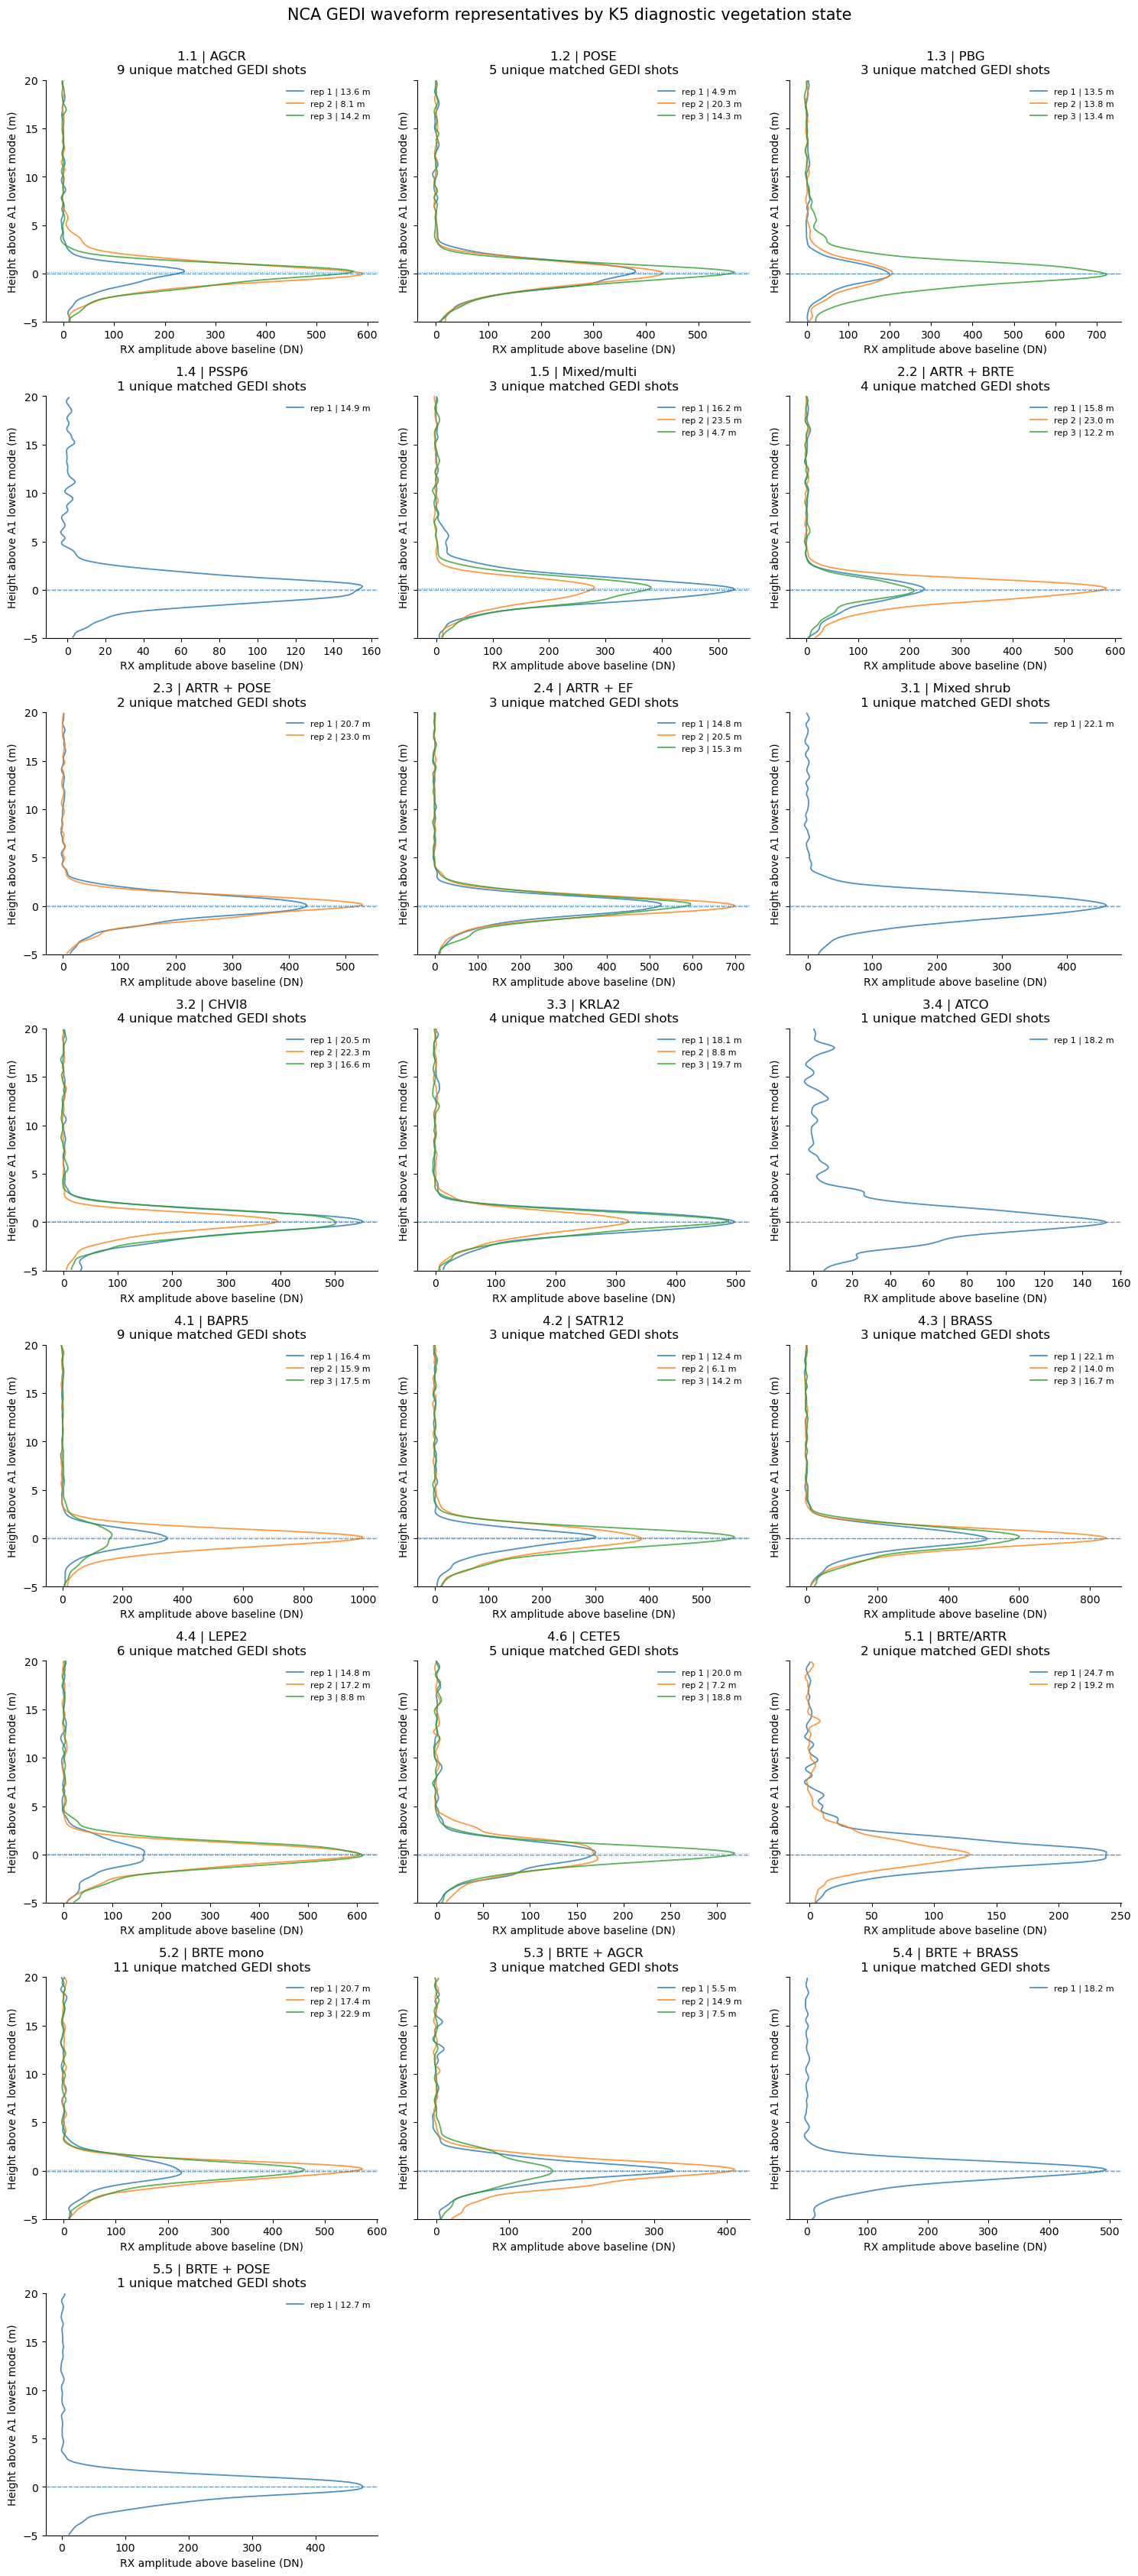

In [24]:
# =============================================================================
# 6. REPRESENTATIVE WAVEFORM ATLAS — A1-REFERENCED
# =============================================================================
state_ids = sorted(representatives["state_id"].astype(str).unique(), key=state_sort_key)
ncols=3
nrows=math.ceil(len(state_ids)/ncols)
fig, axes = plt.subplots(nrows,ncols,figsize=(15,4.2*nrows),sharey=True)
axes=np.asarray(axes).reshape(-1)

for ax,sid in zip(axes,state_ids):
    g=representatives.loc[representatives["state_id"].astype(str)==sid].sort_values("representative_rank")
    for row in g.itertuples(index=False):
        wave=read_l1b_vertical_waveform(row.gedi_granule_key,row.gedi_beam,row.gedi_shot_number)
        a1=float(row.gedi_elev_lowestmode_a1)
        h=wave["z_m"]-a1
        use=(h>=HEIGHT_MIN_M)&(h<=HEIGHT_MAX_M)
        ax.plot(wave["waveform_bc"][use],h[use],lw=1.3,alpha=.8,
                label=f"rep {int(row.representative_rank)} | {row.gedi_distance_m:.1f} m")
        a5rel=float(row.gedi_elev_lowestmode_a5)-a1
        if HEIGHT_MIN_M<=a5rel<=HEIGHT_MAX_M:
            ax.axhline(a5rel,ls=":",lw=.8,alpha=.45)
    ax.axhline(0,ls="--",lw=1,alpha=.65)
    n_avail=int(coverage.loc[coverage["state_id"].astype(str)==sid,"n_unique_gedi_shots"].iloc[0])
    ax.set_title(f"{sid} | {DIAGNOSTIC_STATE_LABELS.get(sid,'')}\n{n_avail} unique matched GEDI shots")
    ax.set_ylim(HEIGHT_MIN_M,HEIGHT_MAX_M)
    ax.set_xlabel("RX amplitude above baseline (DN)")
    ax.set_ylabel("Height above A1 lowest mode (m)")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(frameon=False,fontsize=8)
for ax in axes[len(state_ids):]: ax.axis("off")
fig.suptitle("NCA GEDI waveform representatives by K5 diagnostic vegetation state",y=1.002,fontsize=15)
fig.tight_layout(); plt.show()

In [25]:
# =============================================================================
# 7. A1/A5 BEHAVIOR BY FIELD STATE — NO EXTERNAL DEM REQUIRED
# =============================================================================
ranked["delta_K_a5_minus_a1"] = pd.to_numeric(ranked["gedi_K_a5"],errors="coerce") - pd.to_numeric(ranked["gedi_K_a1"],errors="coerce")
ranked["delta_lowestmode_a5_minus_a1_m"] = pd.to_numeric(ranked["gedi_elev_lowestmode_a5"],errors="coerce") - pd.to_numeric(ranked["gedi_elev_lowestmode_a1"],errors="coerce")

state_a1a5 = (
    ranked.drop_duplicates(subset=["state_id","gedi_granule_key","gedi_beam","gedi_shot_number"])
    .groupby(["state_id","state_label"],dropna=False)
    .agg(
        n_unique_shots=("gedi_shot_number","size"),
        median_K_a1=("gedi_K_a1","median"),
        median_K_a5=("gedi_K_a5","median"),
        pct_a5_more_modes=("delta_K_a5_minus_a1",lambda s:100*np.mean(pd.to_numeric(s,errors="coerce")>0)),
        median_A5_minus_A1_lowestmode_m=("delta_lowestmode_a5_minus_a1_m","median"),
        p05_A5_minus_A1_lowestmode_m=("delta_lowestmode_a5_minus_a1_m",lambda s:np.nanpercentile(pd.to_numeric(s,errors="coerce"),5)),
    )
    .reset_index()
    .sort_values("state_id",key=lambda s:s.map(state_sort_key))
)
display(state_a1a5)

,state_id,state_label,n_unique_shots,median_K_a1,median_K_a5,pct_a5_more_modes,median_A5_minus_A1_lowestmode_m,p05_A5_minus_A1_lowestmode_m
0,1.1,AGCR,9,1.0,1.0,11.111111,0.074646,-10.555518
1,1.2,POSE,5,1.0,1.0,20.000000,0.074890,-5.596484
2,1.3,PBG,3,1.0,1.0,33.333333,0.000000,-6.912817
3,1.4,PSSP6,1,1.0,1.0,0.000000,0.037476,0.037476
4,1.5,Mixed/multi,3,1.0,1.0,33.333333,0.112305,0.044849
5,2.2,ARTR + BRTE,4,1.0,1.0,25.000000,0.074829,-4.637274
6,2.3,ARTR + POSE,2,1.0,1.0,0.000000,0.074860,0.041049
7,2.4,ARTR + EF,3,1.0,1.0,33.333333,0.074890,-6.701312
8,3.1,Mixed shrub,1,1.0,1.0,0.000000,0.074646,0.074646
9,3.2,CHVI8,4,1.0,1.0,0.000000,0.056091,-0.026190


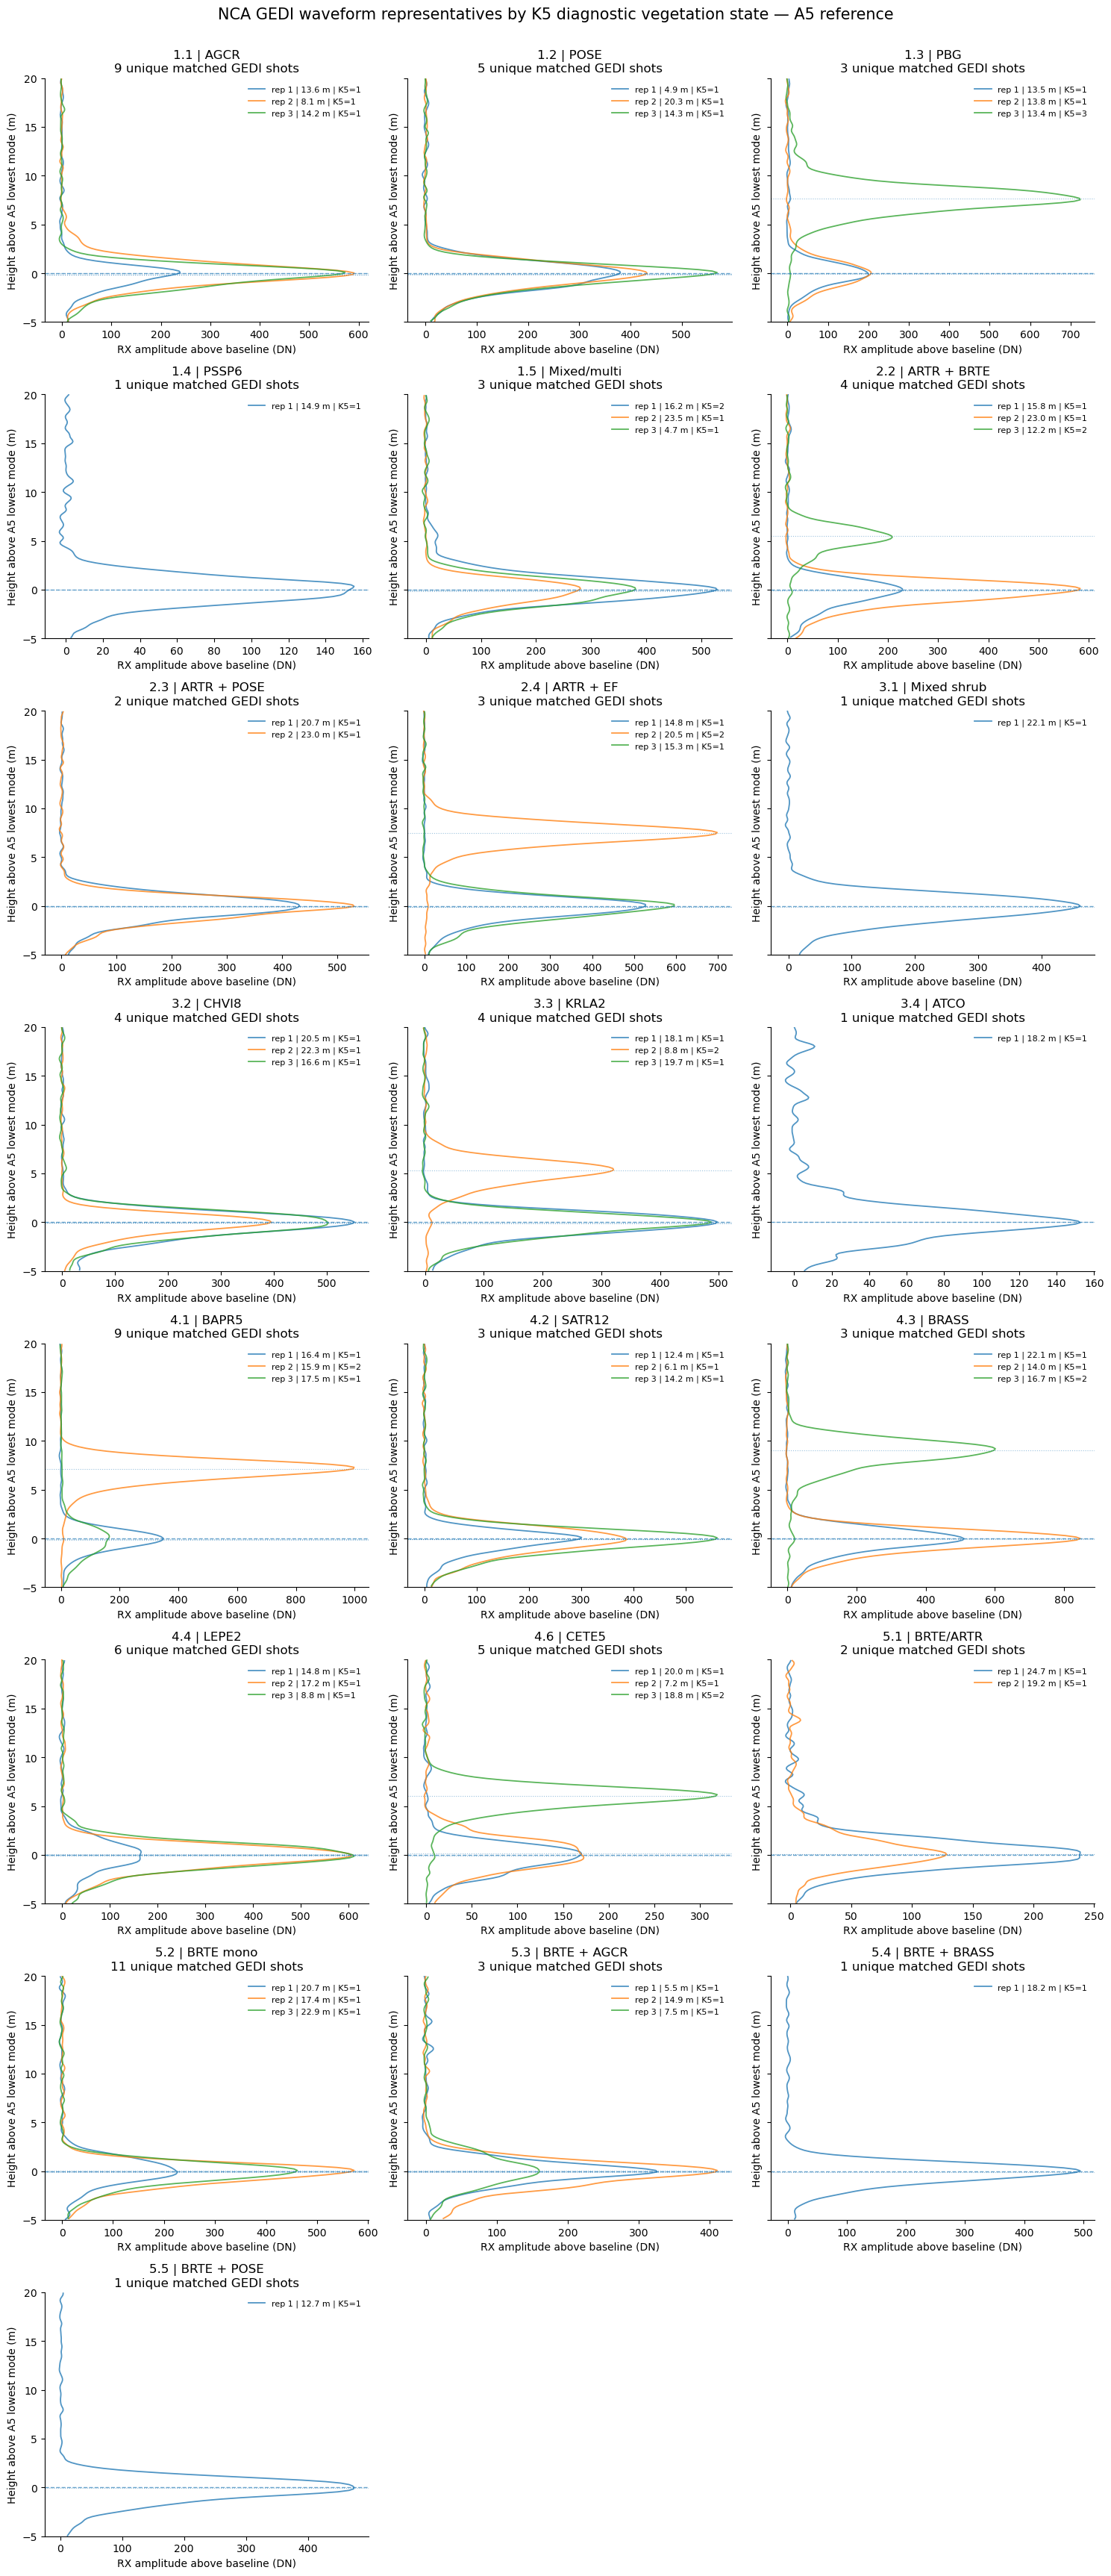

In [26]:
# =============================================================================
# A5-REFERENCED REPRESENTATIVE WAVEFORM ATLAS
#
# SAME field-GEDI representative shots as the A1 atlas.
# ONLY the vertical reference changes:
#
#     h_A5 = z - z_lowestmode_A5
#
# This allows a direct comparison of how the A5 lowest-mode selection
# relocates otherwise identical L1B waveforms.
# =============================================================================

state_ids = sorted(
    representatives["state_id"]
    .dropna()
    .astype(str)
    .unique(),
    key=state_sort_key,
)


ncols = 3

nrows = math.ceil(
    len(state_ids)
    / ncols
)


fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        15,
        4.3 * nrows,
    ),
    sharex=False,
    sharey=True,
)


axes = np.asarray(
    axes
).reshape(
    -1
)


for ax, state_id in zip(
    axes,
    state_ids,
):

    subset = (
        representatives.loc[
            representatives[
                "state_id"
            ]
            .astype(str)
            == str(state_id)
        ]
        .sort_values(
            "representative_rank"
        )
    )


    label = (
        DIAGNOSTIC_STATE_LABELS.get(
            str(state_id),
            "",
        )
    )


    for row in subset.itertuples(
        index=False
    ):

        wave = read_l1b_vertical_waveform(
            row.gedi_granule_key,
            row.gedi_beam,
            row.gedi_shot_number,
        )


        # -------------------------------------------------------------
        # A5 vertical reference
        # -------------------------------------------------------------

        a5_ground = float(
            row.gedi_elev_lowestmode_a5
        )


        h_a5 = (
            wave["z_m"]
            - a5_ground
        )


        use = (
            (h_a5 >= HEIGHT_MIN_M)
            &
            (h_a5 <= HEIGHT_MAX_M)
        )


        rank = int(
            row.representative_rank
        )


        k5 = (
            int(
                row.gedi_K_a5
            )
            if pd.notna(
                row.gedi_K_a5
            )
            else -1
        )


        ax.plot(
            wave["waveform_bc"][
                use
            ],
            h_a5[
                use
            ],
            linewidth=1.3,
            alpha=0.78,
            label=(
                f"rep {rank} | "
                f"{row.gedi_distance_m:.1f} m | "
                f"K5={k5}"
            ),
        )


        # -------------------------------------------------------------
        # Show A1 lowest mode relative to the A5 origin
        # -------------------------------------------------------------

        a1_relative_to_a5 = (
            float(
                row.gedi_elev_lowestmode_a1
            )
            - a5_ground
        )


        if (
            HEIGHT_MIN_M
            <= a1_relative_to_a5
            <= HEIGHT_MAX_M
        ):

            ax.axhline(
                a1_relative_to_a5,
                linewidth=0.8,
                linestyle=":",
                alpha=0.45,
            )


    # A5 lowest mode = zero
    ax.axhline(
        0,
        linewidth=1.0,
        linestyle="--",
        alpha=0.65,
    )


    n_available = int(
        coverage.loc[
            coverage[
                "state_id"
            ]
            .astype(str)
            == str(state_id),
            "n_unique_gedi_shots",
        ].iloc[0]
    )


    ax.set_title(
        f"{state_id} | {label}\n"
        f"{n_available} unique matched GEDI shots"
    )


    ax.set_ylim(
        HEIGHT_MIN_M,
        HEIGHT_MAX_M,
    )


    ax.set_xlabel(
        "RX amplitude above baseline (DN)"
    )


    ax.set_ylabel(
        "Height above A5 lowest mode (m)"
    )


    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


    ax.legend(
        frameon=False,
        fontsize=8,
    )


for ax in axes[
    len(state_ids):
]:

    ax.axis(
        "off"
    )


fig.suptitle(
    "NCA GEDI waveform representatives by K5 diagnostic vegetation state — A5 reference",
    y=1.002,
    fontsize=15,
)


fig.tight_layout()

plt.show()

In [27]:
# =============================================================================
# ALL FIELD-MATCHED GEDI SHOTS WITH A5 K >= 2
# =============================================================================

shot_keys = [
    "gedi_granule_key",
    "gedi_beam",
    "gedi_shot_number",
]


matched_k2plus = (
    matched.loc[
        pd.to_numeric(
            matched["gedi_K_a5"],
            errors="coerce",
        )
        >= 2
    ]
    .copy()
)


# One record per state × GEDI shot.
# A single GEDI footprint can be near more than one field Plot-Year record,
# so deduplicate before summarizing.
matched_k2plus_unique = (
    matched_k2plus
    .sort_values(
        [
            "state_id",
            "gedi_distance_m",
        ]
    )
    .drop_duplicates(
        subset=[
            "state_id",
            *shot_keys,
        ]
    )
    .reset_index(drop=True)
)


print(
    "Field-matched A5 K>=2 state-shot associations:",
    f"{len(matched_k2plus_unique):,}",
)

print(
    "Unique GEDI shots represented:",
    f"{matched_k2plus_unique[shot_keys].drop_duplicates().shape[0]:,}",
)

print(
    "Diagnostic states represented:",
    matched_k2plus_unique["state_id"].nunique(),
)


# -----------------------------------------------------------------------------
# Summary by vegetation state
# -----------------------------------------------------------------------------

k2plus_by_state = (
    matched_k2plus_unique
    .groupby(
        [
            "state_id",
            "state_label",
        ],
        dropna=False,
    )
    .agg(
        n_k2plus_shots=(
            "gedi_shot_number",
            "size",
        ),
        median_K5=(
            "gedi_K_a5",
            "median",
        ),
        max_K5=(
            "gedi_K_a5",
            "max",
        ),
        median_distance_m=(
            "gedi_distance_m",
            "median",
        ),
        median_A5_minus_A1_ground_m=(
            "gedi_elev_lowestmode_a5",
            lambda s:
                np.nanmedian(
                    pd.to_numeric(
                        s,
                        errors="coerce",
                    ).to_numpy()
                    -
                    pd.to_numeric(
                        matched_k2plus_unique.loc[
                            s.index,
                            "gedi_elev_lowestmode_a1",
                        ],
                        errors="coerce",
                    ).to_numpy()
                ),
        ),
    )
    .reset_index()
    .sort_values(
        "state_id",
        key=lambda s: s.map(state_sort_key),
    )
)


display(
    k2plus_by_state
)

Field-matched A5 K>=2 state-shot associations: 12
Unique GEDI shots represented: 12
Diagnostic states represented: 11


,state_id,state_label,n_k2plus_shots,median_K5,max_K5,median_distance_m,median_A5_minus_A1_ground_m
0,1.1,AGCR,1,3.0,3.0,21.083664,-17.592529
1,1.2,POSE,1,2.0,2.0,19.561140,-7.004944
2,1.3,PBG,1,3.0,3.0,13.392832,-7.680908
3,1.5,Mixed/multi,1,2.0,2.0,16.232574,0.037354
4,2.2,ARTR + BRTE,1,2.0,2.0,12.226571,-5.468811
5,2.4,ARTR + EF,1,2.0,2.0,20.497080,-7.454224
6,3.3,KRLA2,1,2.0,2.0,8.834028,-5.318420
7,4.1,BAPR5,2,2.0,2.0,14.357427,-7.640381
8,4.3,BRASS,1,2.0,2.0,16.677119,-9.019897
9,4.4,LEPE2,1,2.0,2.0,15.505203,-4.829651


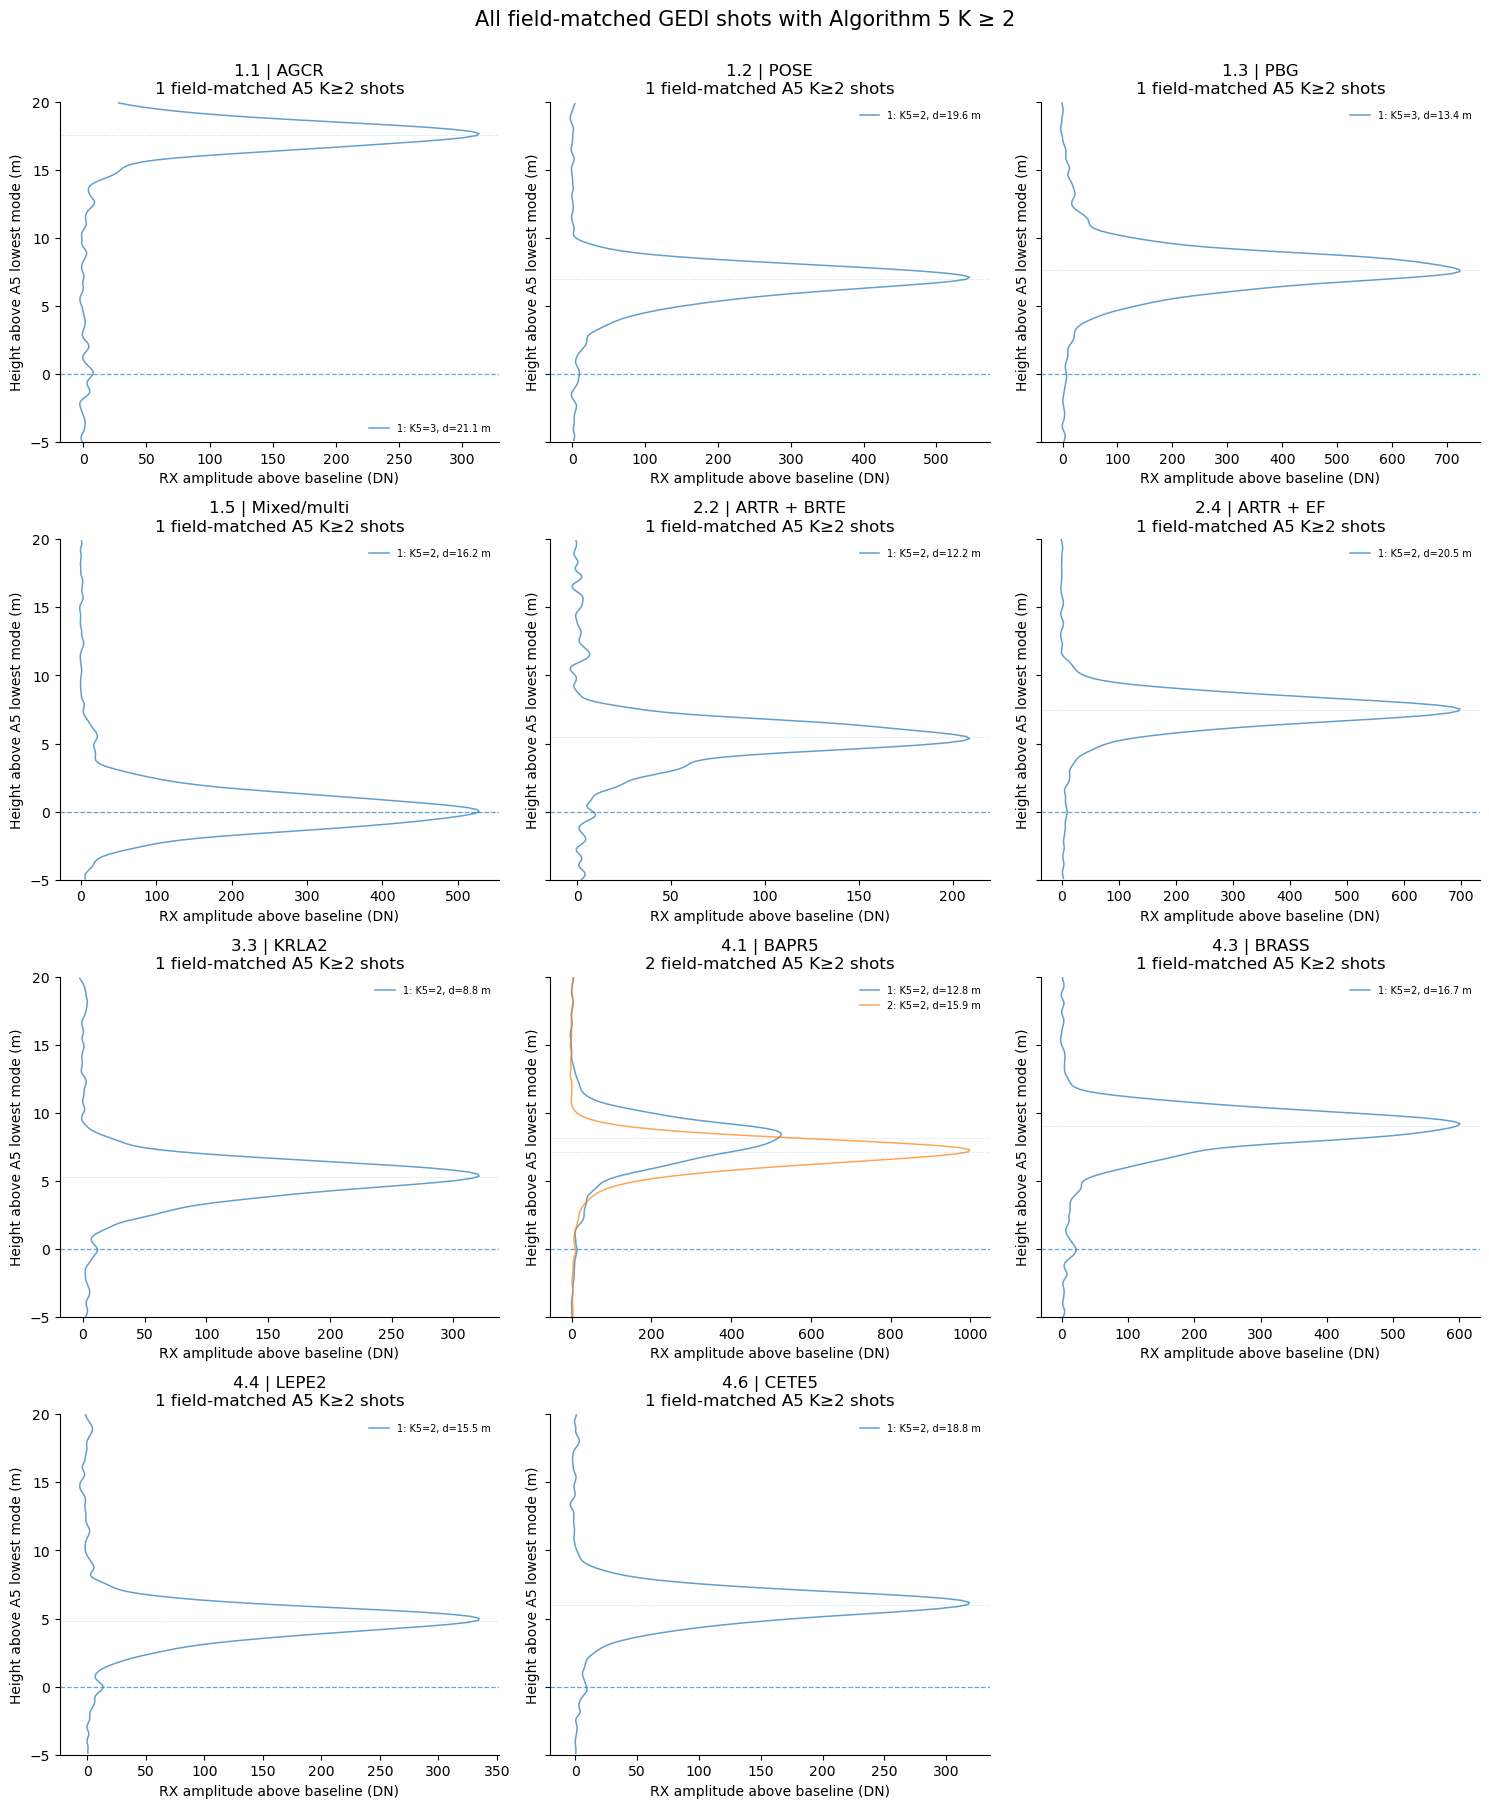

In [28]:
# =============================================================================
# ATLAS OF ALL FIELD-MATCHED A5 K>=2 SHOTS
#
# A5 reference:
#   h = z - z_lowestmode_A5
# =============================================================================

state_ids_k2plus = sorted(
    matched_k2plus_unique[
        "state_id"
    ]
    .dropna()
    .astype(str)
    .unique(),
    key=state_sort_key,
)


ncols = 3
nrows = math.ceil(
    len(state_ids_k2plus)
    / ncols
)


fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        15,
        4.5 * nrows,
    ),
    sharey=True,
)


axes = np.asarray(
    axes
).reshape(-1)


for ax, state_id in zip(
    axes,
    state_ids_k2plus,
):

    subset = (
        matched_k2plus_unique.loc[
            matched_k2plus_unique[
                "state_id"
            ].astype(str)
            == str(state_id)
        ]
        .sort_values(
            [
                "gedi_K_a5",
                "gedi_distance_m",
            ]
        )
    )


    state_label = (
        DIAGNOSTIC_STATE_LABELS.get(
            str(state_id),
            "",
        )
    )


    for j, row in enumerate(
        subset.itertuples(
            index=False
        ),
        start=1,
    ):

        wave = read_l1b_vertical_waveform(
            row.gedi_granule_key,
            row.gedi_beam,
            row.gedi_shot_number,
        )


        a5_ground = float(
            row.gedi_elev_lowestmode_a5
        )

        h_a5 = (
            wave["z_m"]
            - a5_ground
        )


        use = (
            (h_a5 >= HEIGHT_MIN_M)
            &
            (h_a5 <= HEIGHT_MAX_M)
        )


        k5 = int(
            row.gedi_K_a5
        )


        ax.plot(
            wave["waveform_bc"][
                use
            ],
            h_a5[
                use
            ],
            linewidth=1.1,
            alpha=0.70,
            label=(
                f"{j}: K5={k5}, "
                f"d={row.gedi_distance_m:.1f} m"
            ),
        )


        # A1 lowest-mode position in the same A5-relative frame.
        a1_rel = (
            float(
                row.gedi_elev_lowestmode_a1
            )
            - a5_ground
        )

        if (
            HEIGHT_MIN_M
            <= a1_rel
            <= HEIGHT_MAX_M
        ):
            ax.axhline(
                a1_rel,
                linestyle=":",
                linewidth=0.7,
                alpha=0.25,
            )


    ax.axhline(
        0,
        linestyle="--",
        linewidth=0.9,
        alpha=0.65,
    )


    ax.set_title(
        f"{state_id} | {state_label}\n"
        f"{len(subset)} field-matched A5 K≥2 shots"
    )

    ax.set_ylim(
        HEIGHT_MIN_M,
        HEIGHT_MAX_M,
    )

    ax.set_xlabel(
        "RX amplitude above baseline (DN)"
    )

    ax.set_ylabel(
        "Height above A5 lowest mode (m)"
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


    # Avoid unreadable legends if one state has many shots.
    if len(subset) <= 12:
        ax.legend(
            frameon=False,
            fontsize=7,
        )


for ax in axes[
    len(state_ids_k2plus):
]:
    ax.axis("off")


fig.suptitle(
    "All field-matched GEDI shots with Algorithm 5 K ≥ 2",
    y=1.002,
    fontsize=15,
)

fig.tight_layout()

plt.show()

In [29]:
# =============================================================================
# CASE TABLE: EVERY FIELD-MATCHED A5 K>=2 SHOT
# =============================================================================

case_table = (
    matched_k2plus_unique[
        [
            "state_id",
            "state_label",
            "PlotID",
            "Year",
            "gedi_distance_m",
            "gedi_granule_key",
            "gedi_beam",
            "gedi_shot_number",
            "gedi_K_a1",
            "gedi_K_a5",
            "gedi_elev_lowestmode_a1",
            "gedi_elev_lowestmode_a5",
            "gedi_rh98_a1",
            "gedi_rh98_a5",
        ]
    ]
    .copy()
)


case_table[
    "A5_minus_A1_lowestmode_m"
] = (
    pd.to_numeric(
        case_table[
            "gedi_elev_lowestmode_a5"
        ],
        errors="coerce",
    )
    -
    pd.to_numeric(
        case_table[
            "gedi_elev_lowestmode_a1"
        ],
        errors="coerce",
    )
)


case_table[
    "A5_minus_A1_RH98_m"
] = (
    pd.to_numeric(
        case_table[
            "gedi_rh98_a5"
        ],
        errors="coerce",
    )
    -
    pd.to_numeric(
        case_table[
            "gedi_rh98_a1"
        ],
        errors="coerce",
    )
)


case_table = case_table.sort_values(
    [
        "gedi_K_a5",
        "A5_minus_A1_lowestmode_m",
    ],
    ascending=[
        False,
        True,
    ],
)


display(
    case_table
)

,state_id,state_label,PlotID,Year,gedi_distance_m,gedi_granule_key,gedi_beam,gedi_shot_number,gedi_K_a1,gedi_K_a5,gedi_elev_lowestmode_a1,gedi_elev_lowestmode_a5,gedi_rh98_a1,gedi_rh98_a5,A5_minus_A1_lowestmode_m,A5_minus_A1_RH98_m
0,1.1,AGCR,20251118_idgaf5,2025,21.083664,O02309_03_T01444_02,BEAM0010,23090200300132599,1.0,3.0,869.400513,851.807983,2.73,19.98,-17.592529,17.25
2,1.3,PBG,212,2018,13.392832,O08977_03_T01291_02,BEAM1000,89770800300134967,1.0,3.0,873.751282,866.070374,4.92,12.52,-7.680908,7.60
9,4.3,BRASS,886,2016,16.677119,O20049_03_T02714_02,BEAM1000,200490800300135664,1.0,2.0,788.036438,779.016541,2.75,11.40,-9.019897,8.65
7,4.1,BAPR5,116,2018,12.814088,O19954_02_T07867_02,BEAM1011,199541100200103280,1.0,2.0,876.993530,868.864441,3.28,11.14,-8.129089,7.86
5,2.4,ARTR + EF,109,2018,20.497080,O02168_02_T05021_02,BEAM1000,21680800200093538,1.0,2.0,969.716858,962.262634,2.77,9.88,-7.454224,7.11
8,4.1,BAPR5,117,2016,15.900767,O02309_03_T01444_02,BEAM1011,23091100300128544,1.0,2.0,895.515076,888.363403,2.50,9.24,-7.151672,6.74
1,1.2,POSE,982,2016,19.561140,O18169_02_T06597_02,BEAM0101,181690500200105035,1.0,2.0,867.352600,860.347656,2.54,9.17,-7.004944,6.63
11,4.6,CETE5,214,2016,18.774636,O02309_03_T01444_02,BEAM0010,23090200300133573,1.0,2.0,913.356323,907.329956,2.65,8.38,-6.026367,5.73
4,2.2,ARTR + BRTE,836,2016,12.226571,O11917_02_T07255_02,BEAM0000,119170000200106073,1.0,2.0,852.476562,847.007751,2.50,7.67,-5.468811,5.17
6,3.3,KRLA2,123,2018,8.834028,O23299_03_T01444_02,BEAM0011,232990300300241406,1.0,2.0,931.496826,926.178406,2.80,7.82,-5.318420,5.02


## Interpretation checklist

Before treating a waveform as characteristic of a vegetation state, check:

- number of unique matched GEDI shots;
- field year versus GEDI acquisition timing;
- whether the morphology repeats across multiple matched plots;
- terrain / acquisition / beam effects;
- whether the pattern survives A1/A5 ground-reference choice;
- whether continuous functional-group composition explains the waveform better than the hard state label.

The immediate purpose is to identify promising state–waveform examples and support for a later formal FINESST analysis.

In [31]:
# =============================================================================
# PARENT-GROUPED GEDI WAVEFORM ATLASES
#
# Produces one figure per K5 parent cluster.
# Run once for A1 and once for A5.
# =============================================================================

def plot_parent_grouped_waveforms(
    representatives,
    reference="A1",
):
    """
    Plot representative GEDI waveforms grouped into separate figures
    by K5 parent vegetation cluster.

    Parameters
    ----------
    representatives : DataFrame
        Representative field-GEDI associations.

    reference : {"A1", "A5"}
        Lowest-mode elevation used as the vertical origin.
    """

    reference = str(
        reference
    ).upper()

    if reference not in {
        "A1",
        "A5",
    }:
        raise ValueError(
            "reference must be 'A1' or 'A5'"
        )


    # -------------------------------------------------------------------------
    # Determine parent clusters actually represented
    # -------------------------------------------------------------------------

    parent_values = (
        pd.to_numeric(
            representatives[
                "parent_cluster_k5"
            ],
            errors="coerce",
        )
        .dropna()
        .astype(int)
        .unique()
    )

    parent_values = sorted(
        parent_values
    )


    # -------------------------------------------------------------------------
    # Plot one figure per parent
    # -------------------------------------------------------------------------

    for parent in parent_values:

        parent_data = (
            representatives.loc[
                pd.to_numeric(
                    representatives[
                        "parent_cluster_k5"
                    ],
                    errors="coerce",
                )
                == parent
            ]
            .copy()
        )


        state_ids = sorted(
            parent_data[
                "state_id"
            ]
            .dropna()
            .astype(str)
            .unique(),
            key=state_sort_key,
        )


        if not state_ids:
            continue


        # ---------------------------------------------------------------------
        # Parent label if available
        # ---------------------------------------------------------------------

        parent_label = None

        if (
            "parent_label_k5"
            in parent_data.columns
        ):

            labels = (
                parent_data[
                    "parent_label_k5"
                ]
                .dropna()
                .astype(str)
                .unique()
            )

            if len(labels):
                parent_label = labels[0]


        if parent_label is None:
            parent_title = (
                f"K5 parent {parent}"
            )

        else:
            parent_title = (
                f"K5 parent {parent} | "
                f"{parent_label}"
            )


        # ---------------------------------------------------------------------
        # Figure geometry
        # ---------------------------------------------------------------------

        n_states = len(
            state_ids
        )

        ncols = min(
            3,
            n_states,
        )

        nrows = math.ceil(
            n_states
            / ncols
        )


        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(
                5.0 * ncols,
                4.5 * nrows,
            ),
            sharey=True,
            squeeze=False,
        )


        axes = axes.ravel()


        # ---------------------------------------------------------------------
        # Individual diagnostic states
        # ---------------------------------------------------------------------

        for ax, state_id in zip(
            axes,
            state_ids,
        ):

            subset = (
                parent_data.loc[
                    parent_data[
                        "state_id"
                    ]
                    .astype(str)
                    == str(state_id)
                ]
                .sort_values(
                    "representative_rank"
                )
            )


            state_label = (
                DIAGNOSTIC_STATE_LABELS.get(
                    str(state_id),
                    "",
                )
            )


            for row in subset.itertuples(
                index=False
            ):

                wave = (
                    read_l1b_vertical_waveform(
                        row.gedi_granule_key,
                        row.gedi_beam,
                        row.gedi_shot_number,
                    )
                )


                # -------------------------------------------------------------
                # Choose vertical reference
                # -------------------------------------------------------------

                if reference == "A1":

                    z_reference = float(
                        row.gedi_elev_lowestmode_a1
                    )

                    z_other = float(
                        row.gedi_elev_lowestmode_a5
                    )

                    k_value = (
                        int(
                            row.gedi_K_a1
                        )
                        if pd.notna(
                            row.gedi_K_a1
                        )
                        else -1
                    )


                else:

                    z_reference = float(
                        row.gedi_elev_lowestmode_a5
                    )

                    z_other = float(
                        row.gedi_elev_lowestmode_a1
                    )

                    k_value = (
                        int(
                            row.gedi_K_a5
                        )
                        if pd.notna(
                            row.gedi_K_a5
                        )
                        else -1
                    )


                height = (
                    wave[
                        "z_m"
                    ]
                    - z_reference
                )


                use = (
                    (
                        height
                        >= HEIGHT_MIN_M
                    )
                    &
                    (
                        height
                        <= HEIGHT_MAX_M
                    )
                )


                rank = int(
                    row.representative_rank
                )


                ax.plot(
                    wave[
                        "waveform_bc"
                    ][
                        use
                    ],
                    height[
                        use
                    ],
                    linewidth=1.3,
                    alpha=0.78,
                    label=(
                        f"rep {rank} | "
                        f"{row.gedi_distance_m:.1f} m | "
                        f"K={k_value}"
                    ),
                )


                # -------------------------------------------------------------
                # Other algorithm's lowest mode in this reference frame
                # -------------------------------------------------------------

                other_relative = (
                    z_other
                    - z_reference
                )


                if (
                    HEIGHT_MIN_M
                    <= other_relative
                    <= HEIGHT_MAX_M
                ):

                    ax.axhline(
                        other_relative,
                        linestyle=":",
                        linewidth=0.8,
                        alpha=0.40,
                    )


            # -------------------------------------------------------------
            # Current algorithm zero
            # -------------------------------------------------------------

            ax.axhline(
                0,
                linestyle="--",
                linewidth=1.0,
                alpha=0.65,
            )


            # -------------------------------------------------------------
            # Total matched support for this state
            # -------------------------------------------------------------

            coverage_row = (
                coverage.loc[
                    coverage[
                        "state_id"
                    ]
                    .astype(str)
                    == str(state_id)
                ]
            )


            if len(
                coverage_row
            ):

                n_available = int(
                    coverage_row[
                        "n_unique_gedi_shots"
                    ].iloc[0]
                )

            else:

                n_available = len(
                    subset
                )


            ax.set_title(
                f"{state_id} | {state_label}\n"
                f"{n_available} unique matched GEDI shots"
            )


            ax.set_ylim(
                HEIGHT_MIN_M,
                HEIGHT_MAX_M,
            )


            ax.set_xlabel(
                "RX amplitude above baseline (DN)"
            )


            ax.set_ylabel(
                f"Height above {reference} "
                "lowest mode (m)"
            )


            ax.spines[
                "top"
            ].set_visible(
                False
            )

            ax.spines[
                "right"
            ].set_visible(
                False
            )


            ax.legend(
                frameon=False,
                fontsize=8,
            )


        # ---------------------------------------------------------------------
        # Hide unused axes
        # ---------------------------------------------------------------------

        for ax in axes[
            len(
                state_ids
            ):
        ]:

            ax.axis(
                "off"
            )


        # ---------------------------------------------------------------------
        # Figure title
        # ---------------------------------------------------------------------

        fig.suptitle(
            f"{parent_title}\n"
            f"GEDI waveform representatives — "
            f"{reference} reference",
            fontsize=15,
            y=1.02,
        )


        fig.tight_layout()

        plt.show()

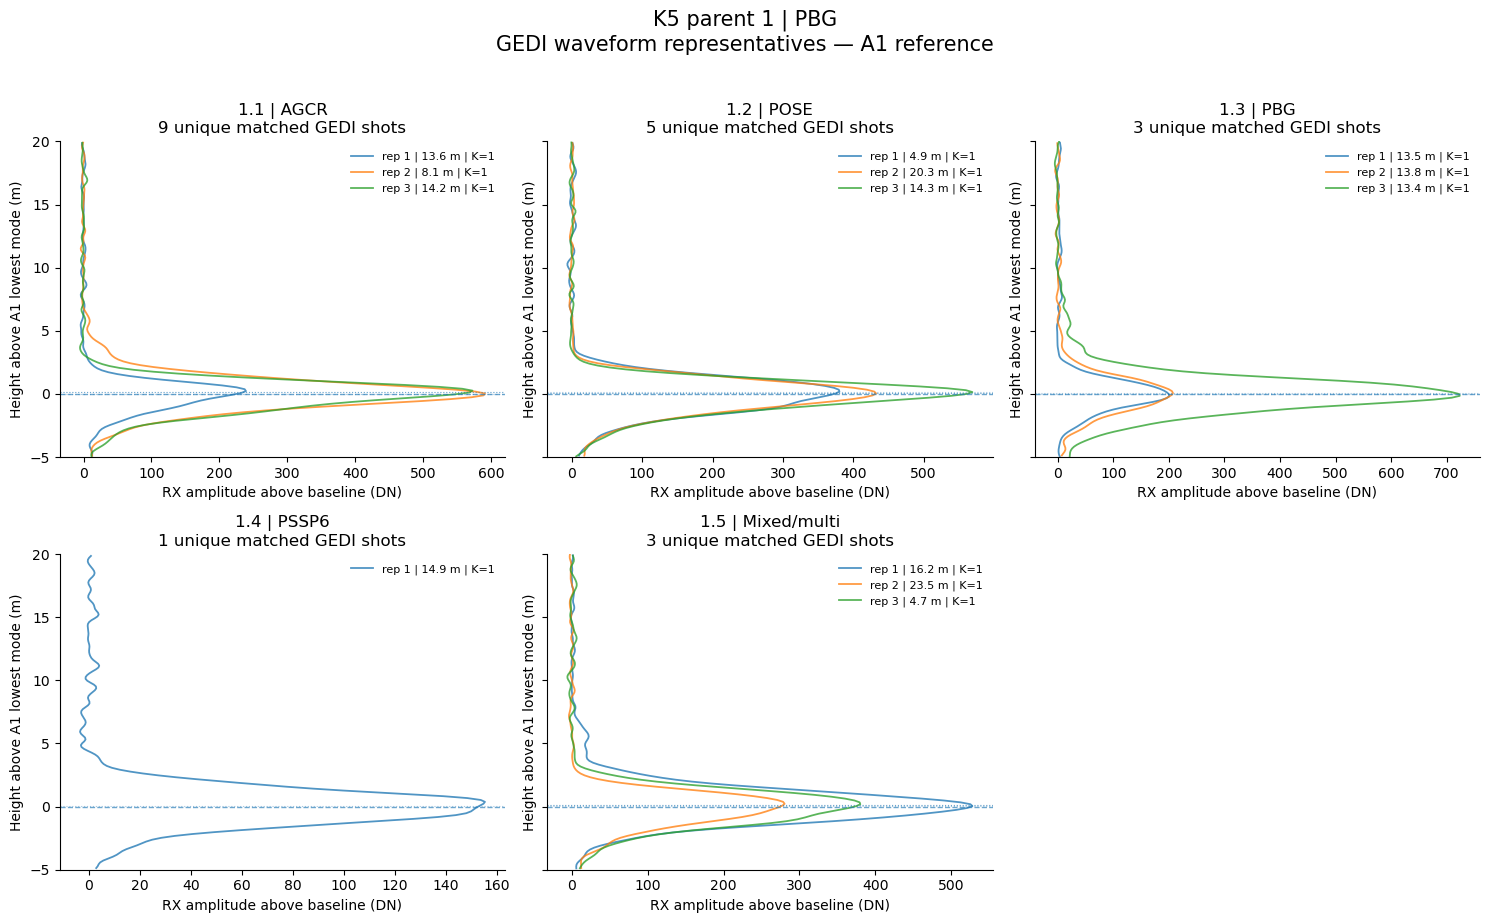

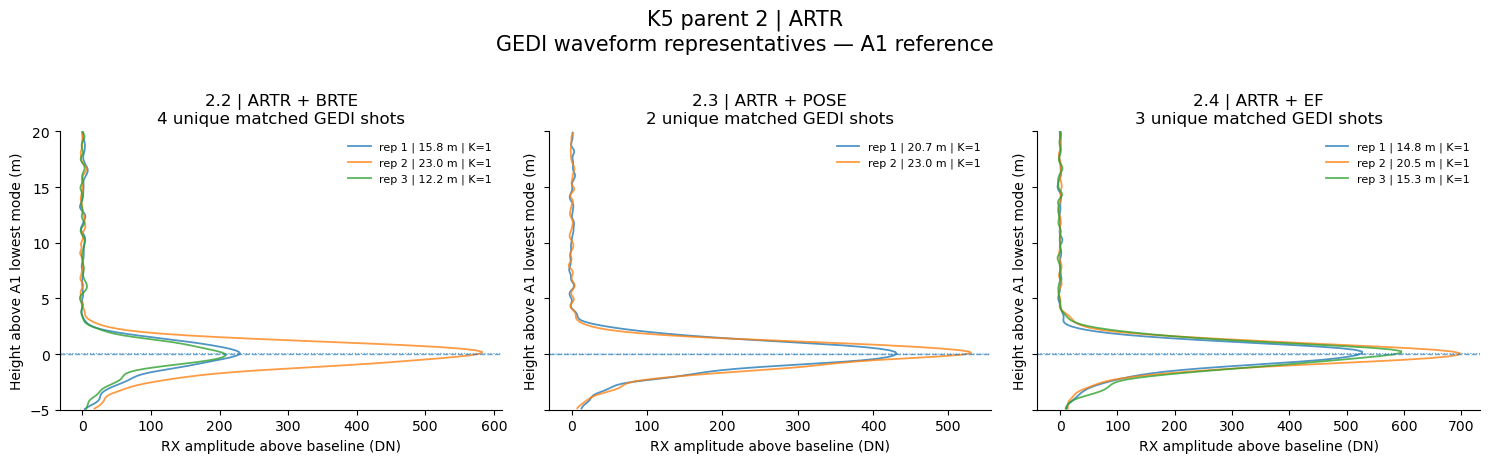

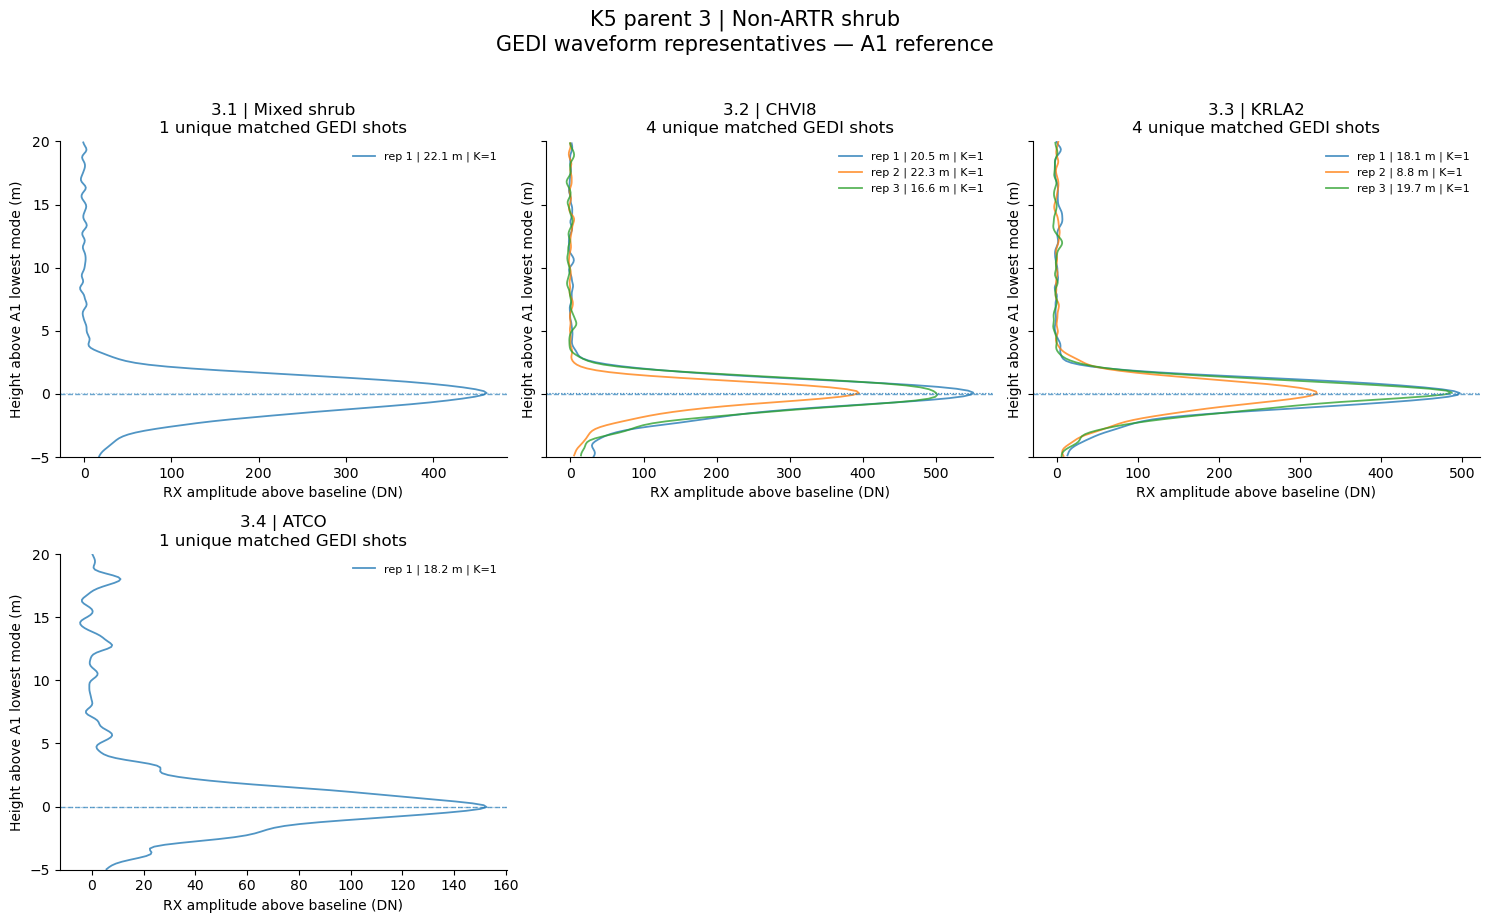

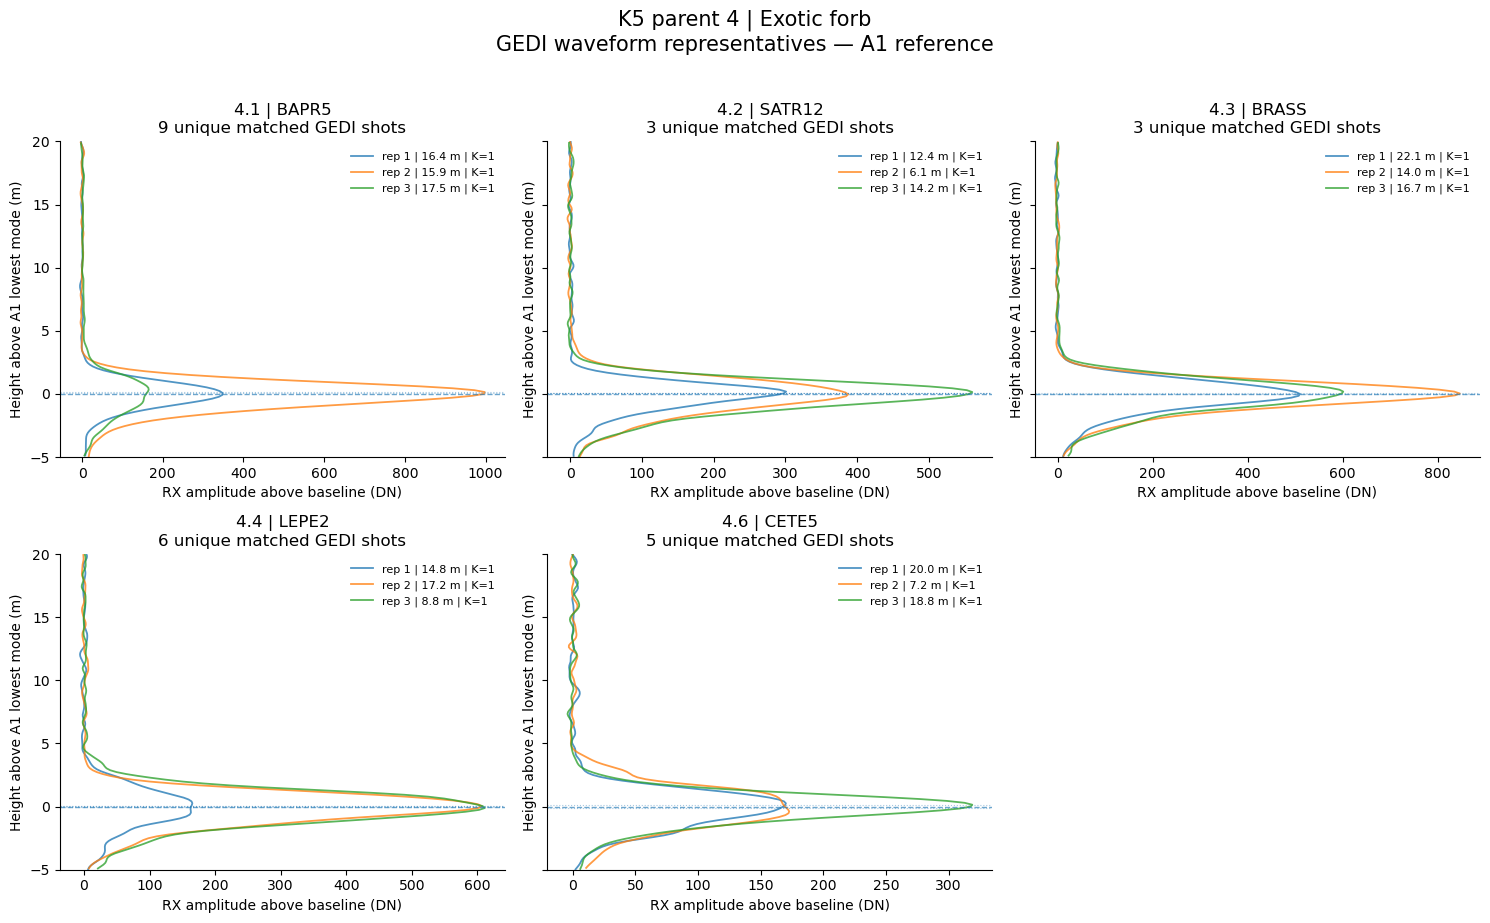

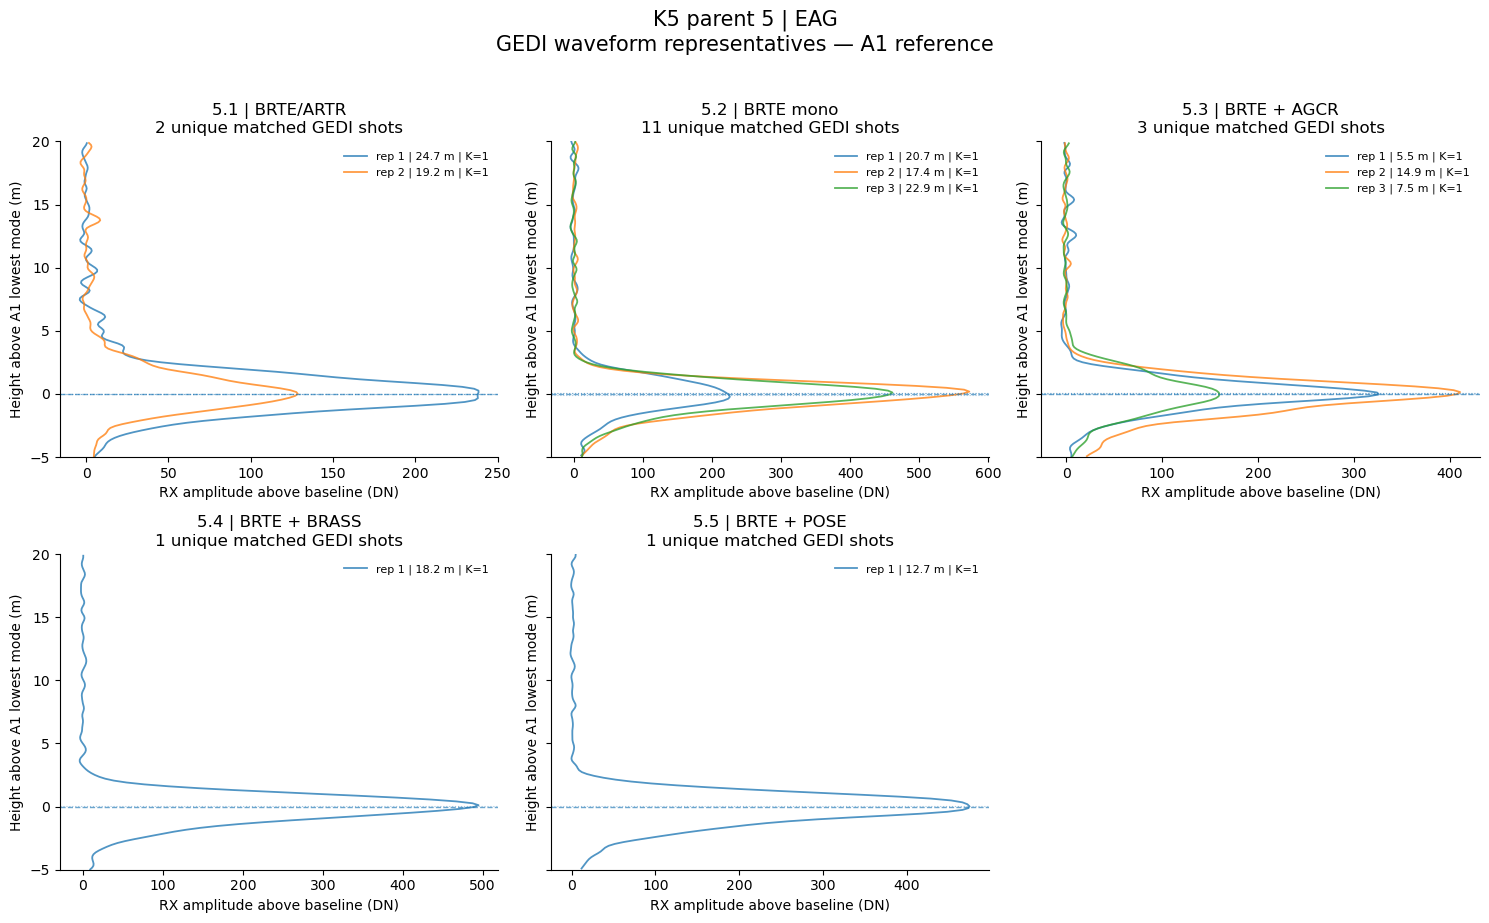

In [32]:
plot_parent_grouped_waveforms(
    representatives,
    reference="A1",
)

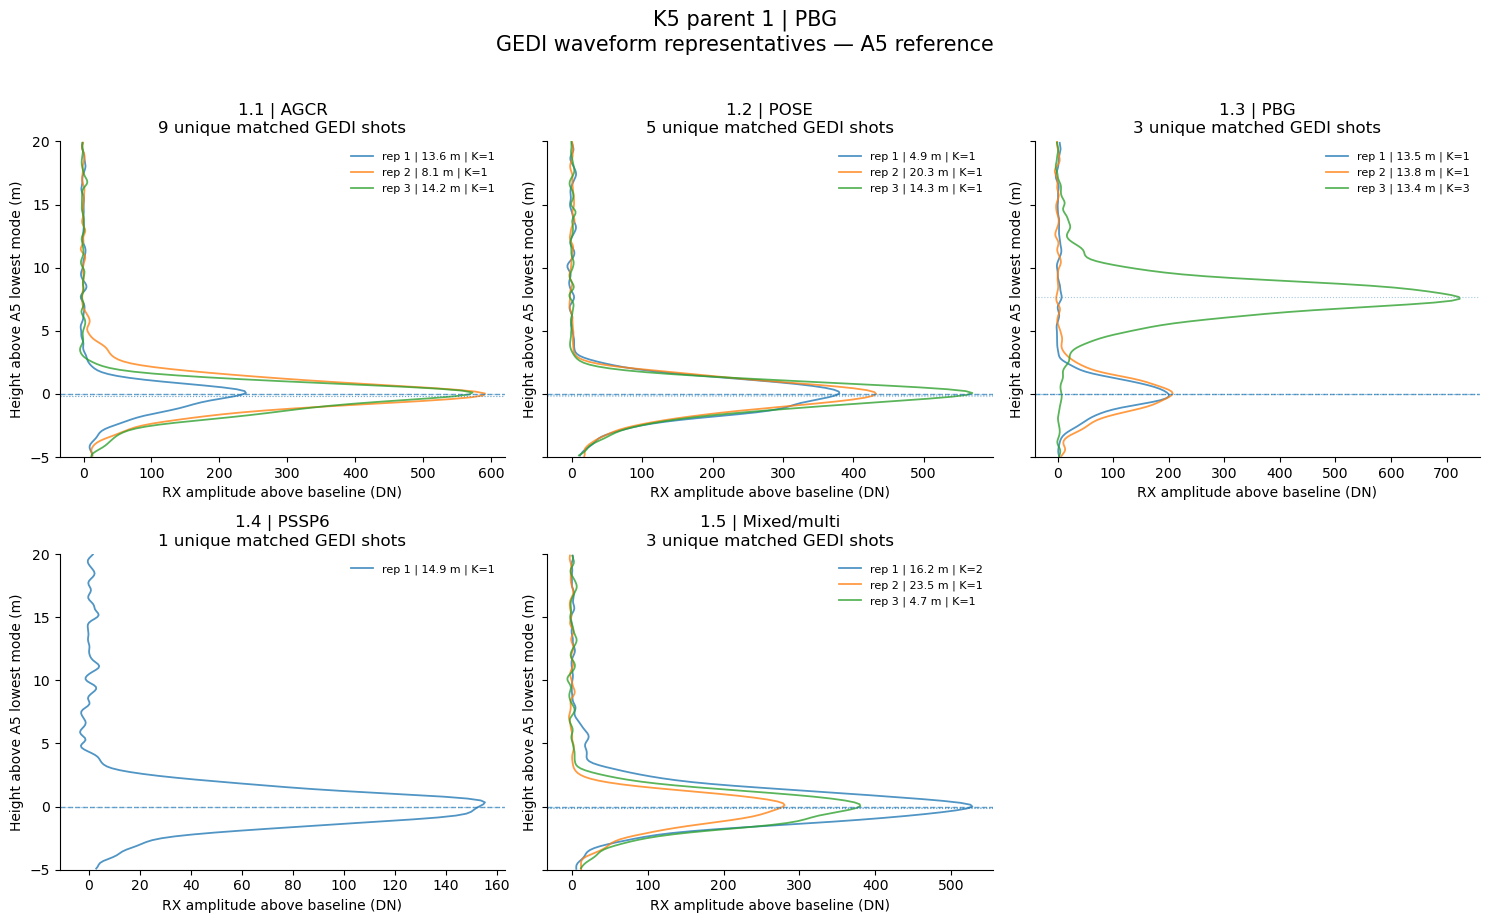

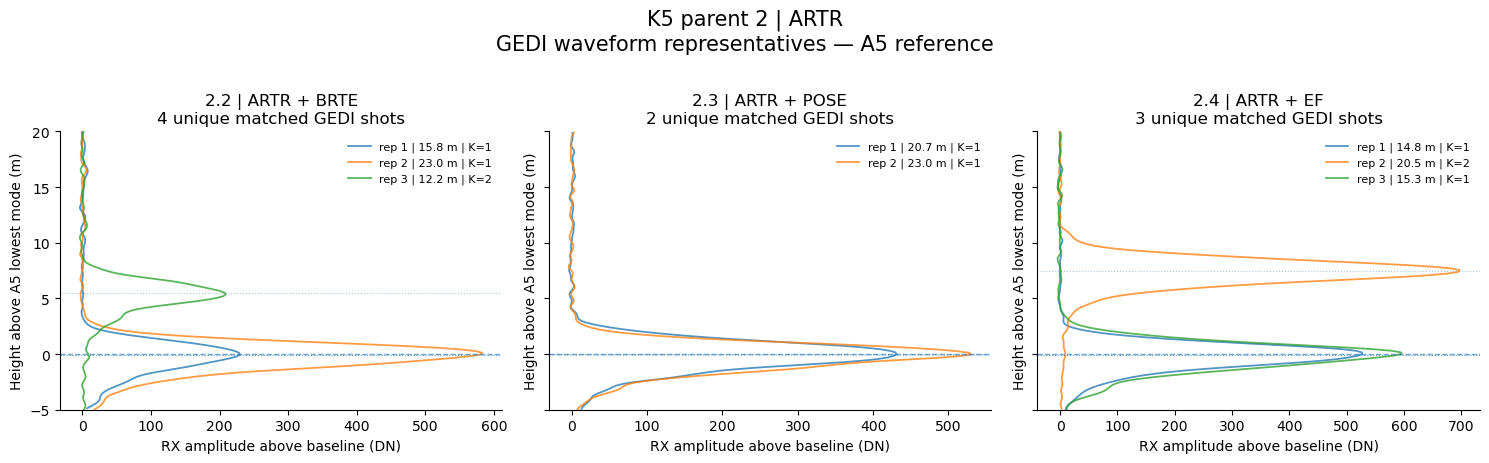

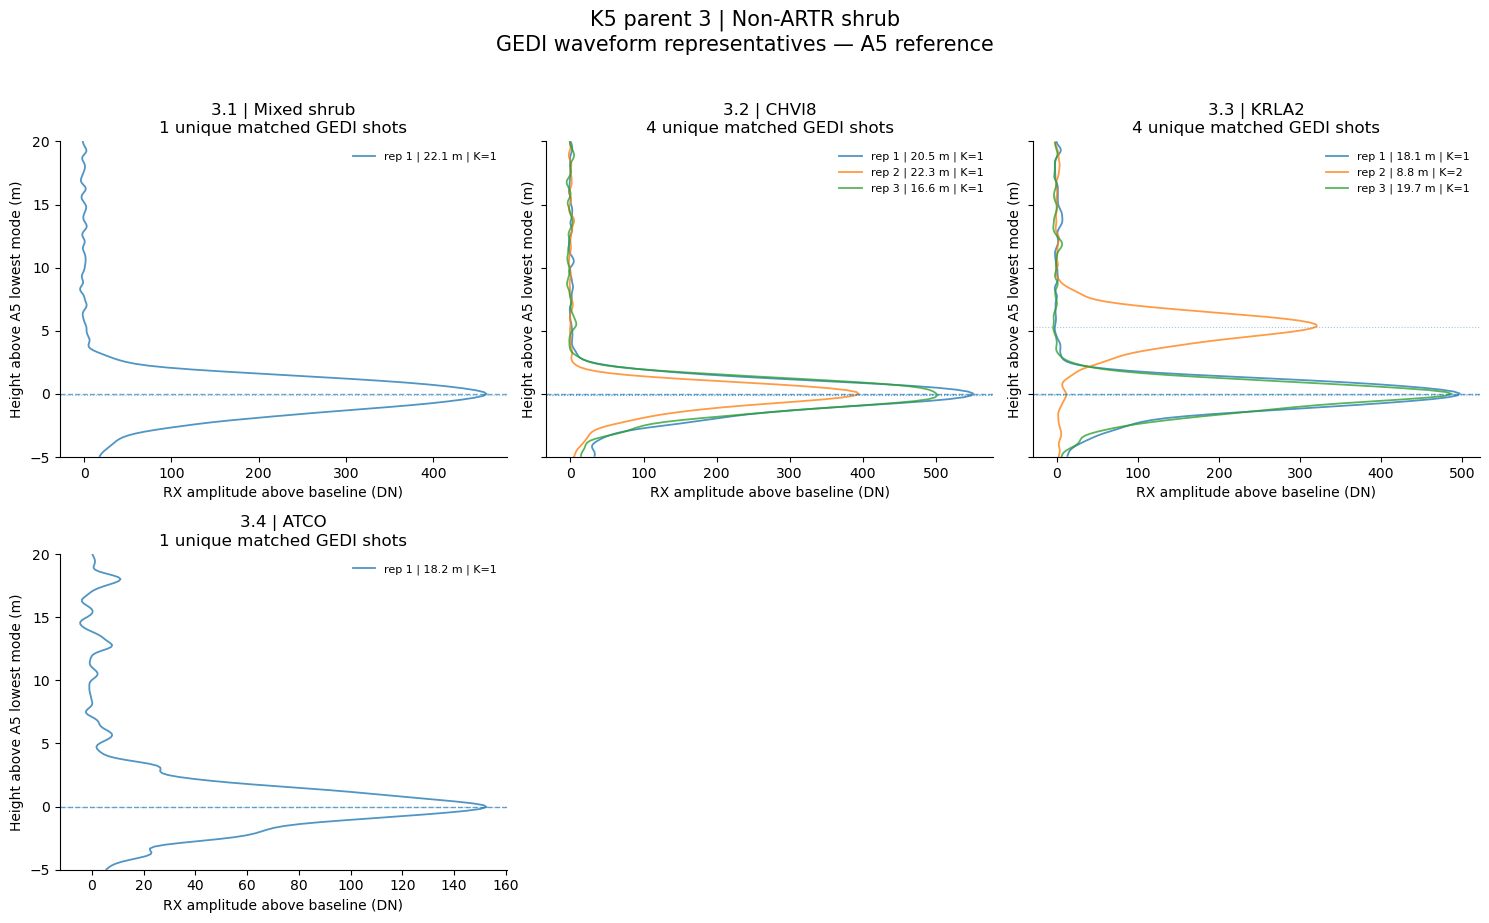

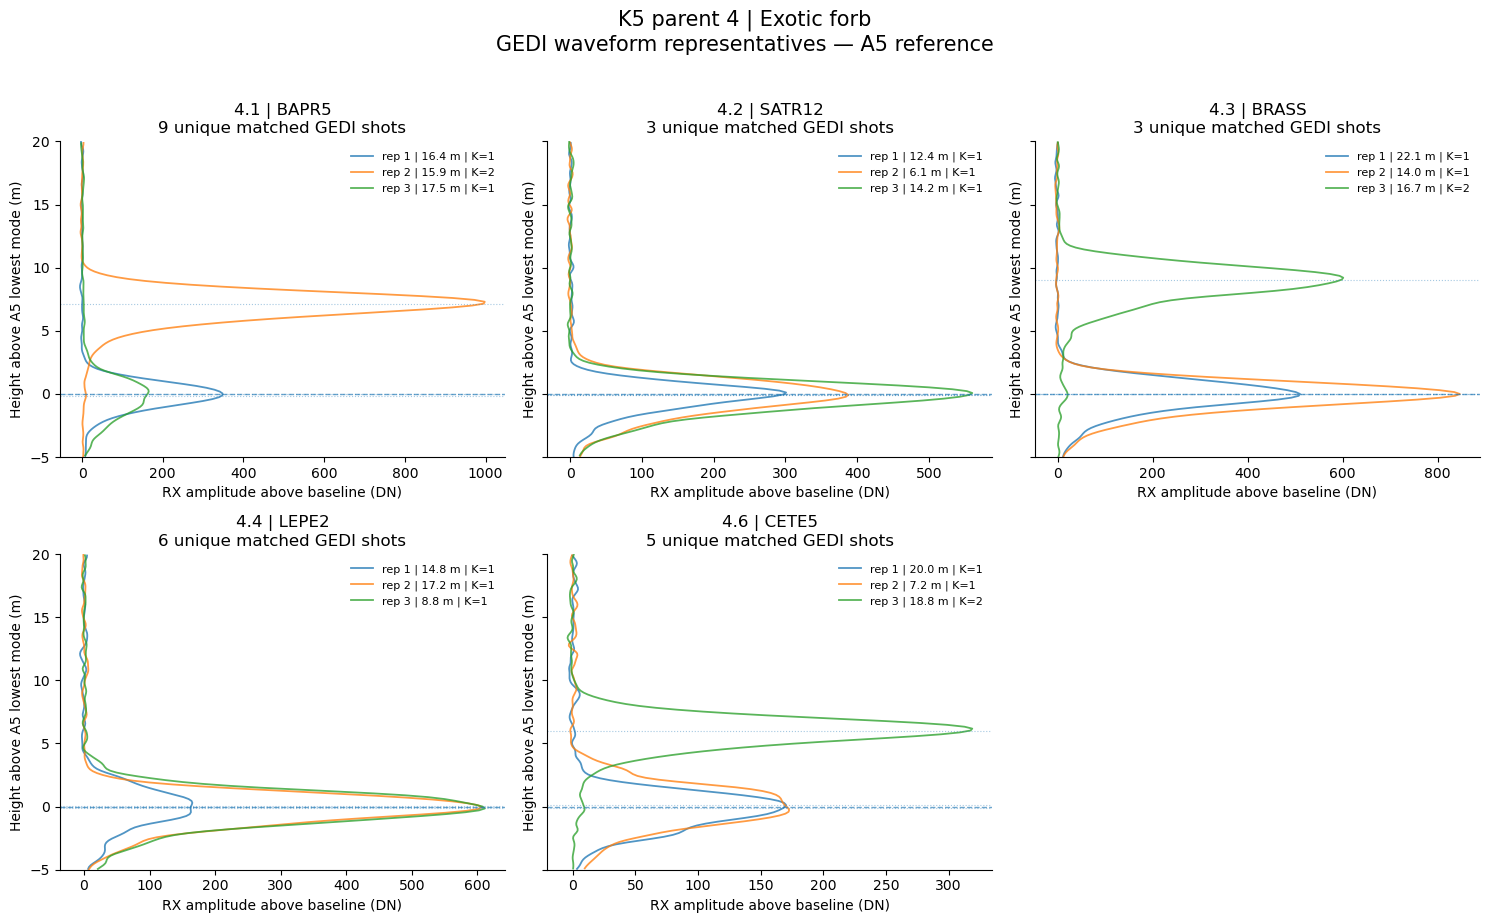

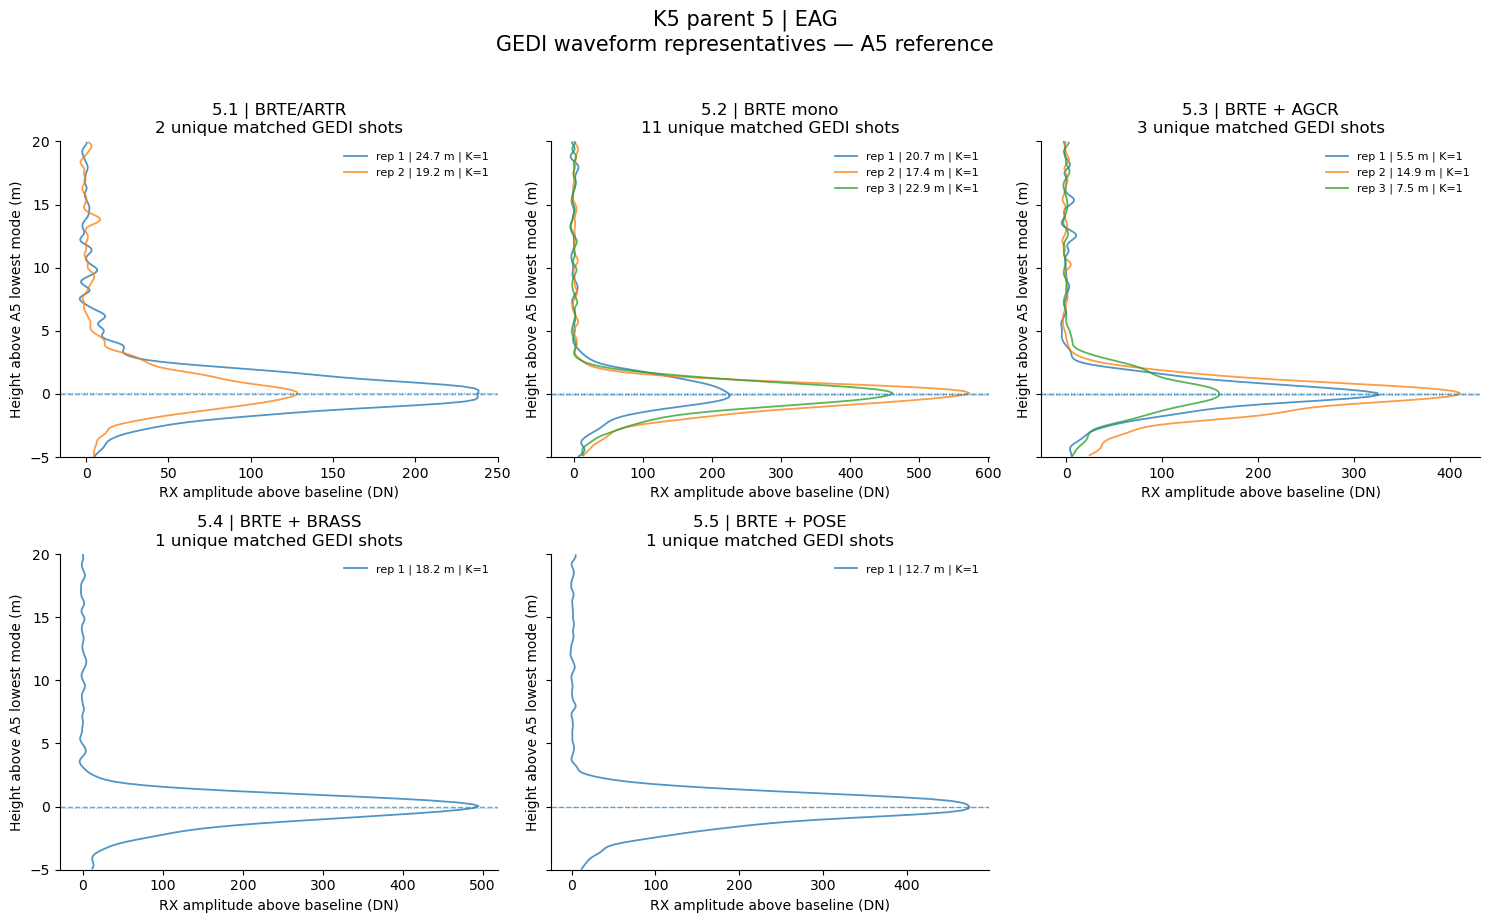

In [33]:
plot_parent_grouped_waveforms(
    representatives,
    reference="A5",
)

In [34]:
# =============================================================================
# DETECTED MODE-COUNT DISTRIBUTIONS
# =============================================================================

def k_distribution(
    df,
    col,
    label,
):
    k = pd.to_numeric(
        df[col],
        errors="coerce",
    )

    out = (
        k.dropna()
        .astype(int)
        .value_counts()
        .sort_index()
        .rename("n")
        .to_frame()
    )

    out["pct"] = (
        100
        * out["n"]
        / out["n"].sum()
    )

    out["algorithm"] = label

    return (
        out.reset_index()
        .rename(
            columns={
                "index": "K",
                col: "K",
            }
        )
    )


# -----------------------------------------------------------------------------
# ALL RETAINED GEDI SHOTS
# -----------------------------------------------------------------------------

dist_a1_all = k_distribution(
    gedi,
    "K_a1",
    "A1",
)

dist_a5_all = k_distribution(
    gedi,
    "K_a5",
    "A5",
)

dist_all = pd.concat(
    [
        dist_a1_all,
        dist_a5_all,
    ],
    ignore_index=True,
)


display(
    dist_all
)

,K,n,pct,algorithm
0,1,472352,99.020802,A1
1,2,3857,0.808556,A1
2,3,676,0.141712,A1
3,4,116,0.024317,A1
4,5,18,0.003773,A1
5,6,4,0.000839,A1
6,1,408057,85.542416,A5
7,2,53699,11.257109,A5
8,3,8637,1.810605,A5
9,4,2527,0.529744,A5


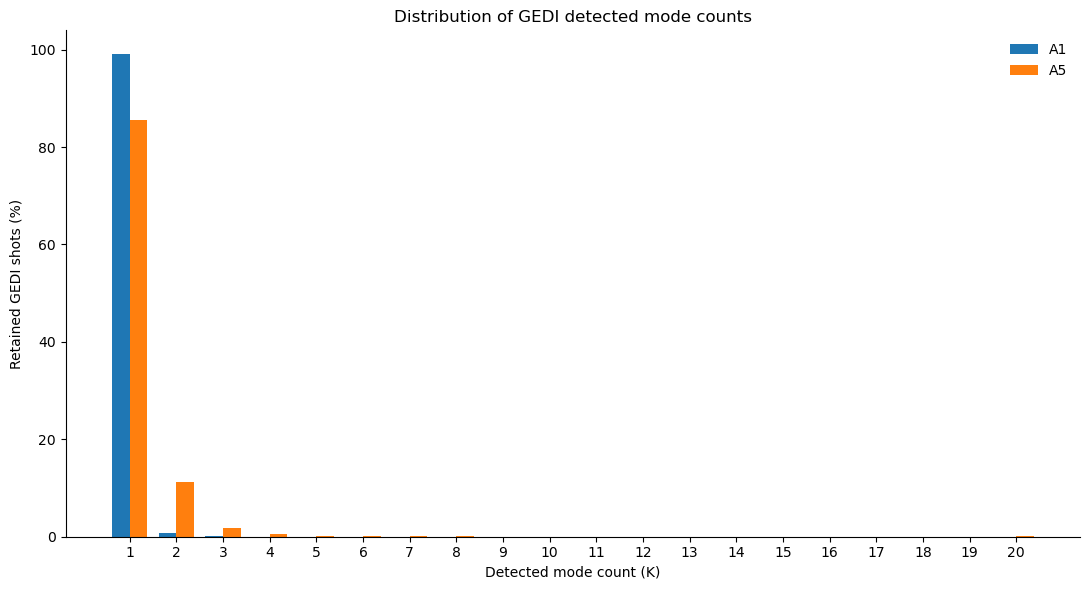

In [35]:
# =============================================================================
# BAR PLOT — ALL RETAINED SHOTS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)


ks = sorted(
    set(
        dist_all["K"]
    )
)


width = 0.38


a1_lookup = (
    dist_a1_all
    .set_index("K")["pct"]
    .to_dict()
)

a5_lookup = (
    dist_a5_all
    .set_index("K")["pct"]
    .to_dict()
)


x = np.arange(
    len(ks)
)


a1_vals = [
    a1_lookup.get(
        k,
        0,
    )
    for k in ks
]

a5_vals = [
    a5_lookup.get(
        k,
        0,
    )
    for k in ks
]


ax.bar(
    x - width / 2,
    a1_vals,
    width,
    label="A1",
)

ax.bar(
    x + width / 2,
    a5_vals,
    width,
    label="A5",
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    ks
)

ax.set_xlabel(
    "Detected mode count (K)"
)

ax.set_ylabel(
    "Retained GEDI shots (%)"
)

ax.set_title(
    "Distribution of GEDI detected mode counts"
)

ax.legend(
    frameon=False
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)

plt.tight_layout()
plt.show()

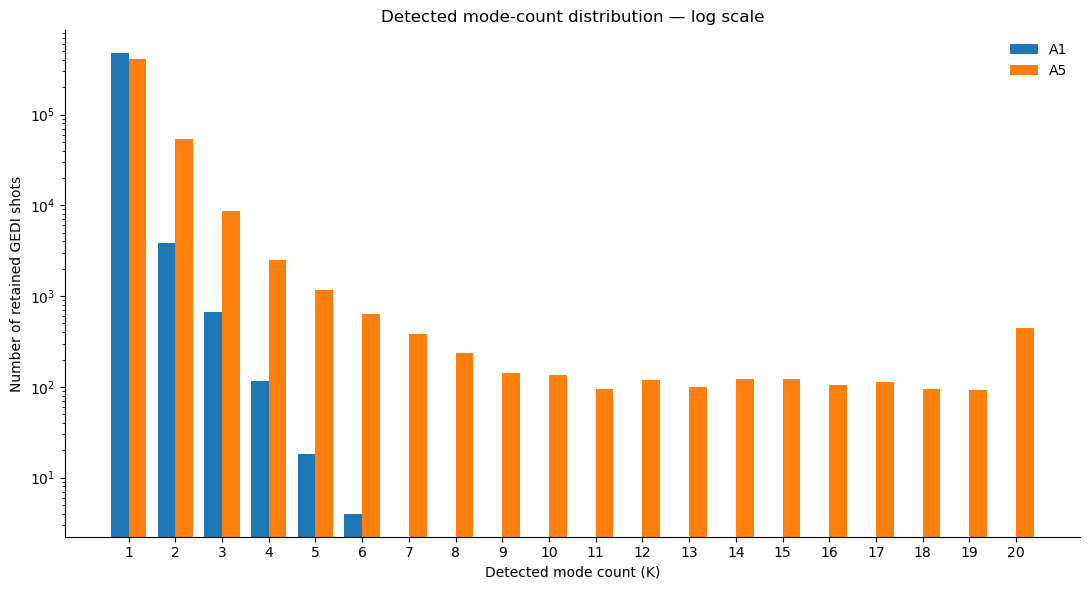

In [36]:
# =============================================================================
# LOG-SCALE COUNT DISTRIBUTION
# =============================================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)


a1_count = (
    dist_a1_all
    .set_index("K")["n"]
    .to_dict()
)

a5_count = (
    dist_a5_all
    .set_index("K")["n"]
    .to_dict()
)


a1_n = [
    a1_count.get(
        k,
        0,
    )
    for k in ks
]

a5_n = [
    a5_count.get(
        k,
        0,
    )
    for k in ks
]


ax.bar(
    x - width / 2,
    a1_n,
    width,
    label="A1",
)

ax.bar(
    x + width / 2,
    a5_n,
    width,
    label="A5",
)


ax.set_yscale(
    "log"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    ks
)

ax.set_xlabel(
    "Detected mode count (K)"
)

ax.set_ylabel(
    "Number of retained GEDI shots"
)

ax.set_title(
    "Detected mode-count distribution — log scale"
)

ax.legend(
    frameon=False
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)

plt.tight_layout()
plt.show()

In [37]:
# =============================================================================
# FIELD-MATCHED GEDI SHOTS ONLY
# =============================================================================

field_shots = (
    matched[
        [
            "gedi_granule_key",
            "gedi_beam",
            "gedi_shot_number",
            "gedi_K_a1",
            "gedi_K_a5",
        ]
    ]
    .drop_duplicates(
        subset=[
            "gedi_granule_key",
            "gedi_beam",
            "gedi_shot_number",
        ]
    )
    .copy()
)


field_shots = field_shots.rename(
    columns={
        "gedi_K_a1":
            "K_a1",

        "gedi_K_a5":
            "K_a5",
    }
)


dist_a1_field = k_distribution(
    field_shots,
    "K_a1",
    "A1",
)

dist_a5_field = k_distribution(
    field_shots,
    "K_a5",
    "A5",
)


display(
    pd.concat(
        [
            dist_a1_field,
            dist_a5_field,
        ],
        ignore_index=True,
    )
)

,K,n,pct,algorithm
0,1,83,100.000000,A1
1,1,71,85.542169,A5
2,2,10,12.048193,A5
3,3,2,2.409639,A5
